# 08 · RSNA y Mendeley: inventario y preparación de la segmentación

## Propósito

Hasta el cuaderno 07, el trabajo se había realizado con SPIDER, un conjunto procedente de cuatro hospitales de un mismo país y cuyas máscaras se utilizaron para entrenar los dos segmentadores empleados en el proyecto. En este cuaderno se incorporan dos conjuntos externos. El primero es RSNA LumbarDISC, publicado como la competición *RSNA 2024 Lumbar Spine Degenerative Classification*, con estudios procedentes de ocho instituciones de seis países. El segundo es el *Lumbar Spine MRI Dataset* de Mendeley, que contiene 515 carpetas de pacientes y notas de radiólogos en las que se menciona la escoliosis. Por ahora, estas notas son la única referencia externa disponible sobre ese hallazgo.

Ninguno de los dos conjuntos incluye máscaras de toda la columna ni ángulos de Cobb. Por eso, antes de segmentarlos, es necesario conocer su contenido y preparar las imágenes. Este cuaderno reúne las tareas que pueden realizarse sin GPU antes de ejecutar TotalSpineSeg. Se leen las cabeceras DICOM y se describen las series según su orientación, grosor de corte, cobertura lateral y escáner. También se recuperan las marcas de nivel anatómico de RSNA, se revisan las notas de los radiólogos, se convierten a NIfTI las series sagitales y se comprueba cada conversión. Finalmente, se selecciona una T1 y una T2 sagitales por estudio y se preparan las dos listas de trabajo para Kaggle. Además, se intenta medir el tiempo de ejecución de TotalSpineSeg en CPU, aunque esa prueba no llegó a completarse en Colab. La segmentación se realiza después en Kaggle mediante un cuaderno auxiliar, y la medición del ángulo sobre las máscaras corresponde al cuaderno 09.

## Preguntas que responde

| Pregunta | Sección |
|---|---|
| ¿Qué contienen los dos archivos y cómo están organizados? | Estructura de los archivos |
| ¿Cuántos estudios y series sagitales hay, y cuáles son sus características de adquisición? | Inventario de RSNA · Inventario de Mendeley |
| ¿Las cabeceras de RSNA conservan la institución o el escáner de cada estudio? | Inventario de RSNA |
| ¿Cada estudio corresponde a un paciente distinto? | Inventario de RSNA · Inventario de Mendeley |
| ¿Cómo registran las notas de Mendeley la escoliosis y en cuántos pacientes aparece? | Las notas de los radiólogos |
| ¿En qué se parecen y en qué se diferencian estas series de las de SPIDER? | Comparación con SPIDER |
| ¿En cuántos estudios marca RSNA la posición de los niveles L1-L2 a L5-S1? | Tablas de RSNA |
| ¿Qué series sagitales se pueden convertir a NIfTI sin errores? | Conversión a NIfTI |
| ¿Se pudo ejecutar TotalSpineSeg en CPU y cuánto avanzó la prueba? | Prueba de TotalSpineSeg en CPU |

## Alcance

El análisis de este cuaderno es **técnico y descriptivo**. Aquí todavía no se mide ningún ángulo; esa etapa corresponde al cuaderno 09, una vez disponibles las máscaras. Las notas de Mendeley recogen lo que un especialista escribió al interpretar cada estudio, pero no contienen mediciones del ángulo de Cobb. Por ello, pueden servir como referencia de escoliosis informada, con las limitaciones propias de los informes clínicos, pero no como una validación del método.

Este trabajo es de investigación y **no constituye una validación clínica ni está destinado al diagnóstico de escoliosis**.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos. Por esa razón, las tablas por estudio, serie e imagen se conservan en una carpeta privada de Drive. En el repositorio solo se publican resultados agregados. Mendeley cuenta con licencia CC BY 4.0, por lo que sus tablas pueden publicarse citando la fuente.

## Fuentes

- **RSNA LumbarDISC.** Competición [RSNA 2024 Lumbar Spine Degenerative Classification](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification) en Kaggle, descargada mediante la API de Kaggle el 29-oct-2026 (archivo de 30,3 GB). Descripción del conjunto en [arXiv:2506.09162](https://arxiv.org/abs/2506.09162) y en la [ficha de RSNA](https://atlas.rsna.org/cards/b9ab56b8-10c1-4104-bca1-a57802f1ba08). Uso no comercial y sin redistribución.
- **Lumbar Spine MRI Dataset.** Sudirman *et al.*, Mendeley Data, versión 2, [doi:10.17632/k57fr854j2.2](https://doi.org/10.17632/k57fr854j2.2), licencia CC BY 4.0.
- **Notas de los radiólogos.** *Radiologists Notes for Lumbar Spine MRI Dataset*, Mendeley Data, versión 2, [doi:10.17632/s6bgczr8s2.2](https://doi.org/10.17632/s6bgczr8s2.2), licencia CC BY 4.0.
- **Inventario de SPIDER.** `inventario_series.csv` del cuaderno 01, utilizado para la comparación.

## Antes de ejecutar: datos necesarios

Este cuaderno se ejecuta en Colab y no necesita GPU. Los siguientes archivos deben estar guardados en Google Drive. Para subir las entradas a Kaggle al final del proceso, también se necesita el token de la cuenta, guardado como secreto de Colab con el nombre `KAGGLE_API_TOKEN` o como archivo `kaggle.json`.

| Archivo | Ruta en Google Drive | Obligatorio |
|---|---|---|
| `rsna-2024-lumbar-spine-degenerative-classification.zip` | `MyDrive/PRL/content/datos/rsna/` | Sí |
| `MRI_Data.zip` | `MyDrive/PRL/content/datos/mendeley/` | Sí |
| `Radiologists Notes for Lumbar Spine MRI Dataset.zip` | `MyDrive/PRL/content/datos/mendeley/` | Sí |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/inventario_series.csv` | Sí |

Los resultados públicos se guardan en `MyDrive/PRL/salidas/resultados_semana4/08_rsna_y_mendeley/`. Los archivos que identifican estudios o imágenes de RSNA, incluidos el inventario, los NIfTI y las listas de trabajo, permanecen en carpetas privadas dentro de `MyDrive/PRL/content/datos/rsna/` y no se publican en el repositorio. Los NIfTI de Mendeley quedan en `MyDrive/PRL/content/datos/mendeley/nifti_sagital/`.

Los dos archivos ZIP se copian primero al disco temporal de Colab. Leer miles de imágenes directamente desde Drive sería mucho más lento. La copia tarda entre 10 y 20 minutos y requiere unos 37 GB de espacio libre. En la ejecución del 29-oct-2026, el cuaderno completo tomó alrededor de dos horas y media, principalmente por la conversión de las series de RSNA.

Las celdas de procesamiento guardan sus avances en Drive. Si Colab se interrumpe, se puede volver a ejecutar el cuaderno desde el principio. Las celdas que ya terminaron recuperan los resultados guardados, mientras que la que quedó incompleta continúa desde el último avance registrado. La única tarea que se repite completa es la copia de los ZIP al disco temporal, porque ese almacenamiento se borra al terminar la sesión.

In [2]:
# 1. Dependencias
!pip -q install pydicom SimpleITK

In [3]:
# 2. Configuración
import os, re, io, json, time, shutil, zipfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_DATOS = DIR_PRL / "content" / "datos"
ZIP_RSNA = DIR_DATOS / "rsna" / "rsna-2024-lumbar-spine-degenerative-classification.zip"
ZIP_MENDELEY = DIR_DATOS / "mendeley" / "MRI_Data.zip"
ZIP_NOTAS = DIR_DATOS / "mendeley" / "Radiologists Notes for Lumbar Spine MRI Dataset.zip"
CSV_INVENTARIO_01 = DIR_PRL / "salidas" / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana4" / "08_rsna_y_mendeley"     # público: solo agregados de RSNA
DIR_PRIVADO_RSNA = DIR_DATOS / "rsna" / "inventario"                                  # privado: nunca se publica
DIR_LOCAL = Path("/content/datos08")                                                  # disco temporal de Colab

TAMANO_ZIP_RSNA = 30_303_207_710      # bytes, archivo descargado de Kaggle el 29-oct-2026
TAMANO_ZIP_MENDELEY = 6_270_535_053   # bytes, archivo de Mendeley Data subido a Drive el 29-oct-2026
SERIES_POR_TANDA = 100                # la lectura de cabeceras guarda su avance en Drive cada tanta cantidad de series

for archivo in (ZIP_RSNA, ZIP_MENDELEY, ZIP_NOTAS, CSV_INVENTARIO_01):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"
for d in (DIR_SALIDA, DIR_PRIVADO_RSNA, DIR_LOCAL):
    d.mkdir(parents=True, exist_ok=True)
print("Salida pública:", DIR_SALIDA)
print("Salida privada de RSNA:", DIR_PRIVADO_RSNA)

Mounted at /content/drive
Salida pública: /content/drive/MyDrive/PRL/salidas/resultados_semana4/08_rsna_y_mendeley
Salida privada de RSNA: /content/drive/MyDrive/PRL/content/datos/rsna/inventario


In [ ]:
# 3. Copia local de los zip, con su tamaño y su huella
def md5_archivo(ruta, bloque=1 << 24):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

def copia_local(origen, tamano_esperado):
    "Copia el zip de Drive al disco de Colab (si no está ya) y comprueba que el tamaño coincide."
    destino = DIR_LOCAL / origen.name
    tamano = origen.stat().st_size
    assert tamano == tamano_esperado, f"{origen.name} pesa {tamano} bytes y se esperaban {tamano_esperado}"
    if not destino.exists() or destino.stat().st_size != tamano:
        libre = shutil.disk_usage(DIR_LOCAL).free
        assert libre > tamano * 1.05, f"No hay espacio en el disco de Colab: {libre / 1e9:.1f} GB libres"
        t0 = time.time()
        shutil.copy(origen, destino)
        print(f"{origen.name}: copiado en {(time.time() - t0) / 60:.1f} min")
    assert destino.stat().st_size == tamano
    return destino

LOCAL_RSNA = copia_local(ZIP_RSNA, TAMANO_ZIP_RSNA)
LOCAL_MENDELEY = copia_local(ZIP_MENDELEY, TAMANO_ZIP_MENDELEY)
HUELLAS = {}
for ruta in (LOCAL_RSNA, LOCAL_MENDELEY, ZIP_NOTAS):
    t0 = time.time()
    HUELLAS[ruta.name] = {"bytes": ruta.stat().st_size, "md5": md5_archivo(ruta)}
    print(f"{ruta.name}: {HUELLAS[ruta.name]['bytes'] / 1e9:.2f} GB | md5 {HUELLAS[ruta.name]['md5']} "
          f"({time.time() - t0:.0f} s)")

rsna-2024-lumbar-spine-degenerative-classification.zip: copiado en 11.8 min
MRI_Data.zip: copiado en 2.0 min
rsna-2024-lumbar-spine-degenerative-classification.zip: 30.30 GB | md5 02eef396fd4f15b24afe78419fda0e33 (189 s)
MRI_Data.zip: 6.27 GB | md5 306901245b20d30380a409656e6467bf (35 s)
Radiologists Notes for Lumbar Spine MRI Dataset.zip: 0.00 GB | md5 41077753cce116a8c8a8d0be47fd3f47 (0 s)


## Estructura de los archivos

Antes de leer las imágenes conviene conocer cómo están organizadas. La celda 4 recorre el contenido de los dos ZIP sin descomprimirlos y muestra las carpetas de primer nivel, las extensiones de los archivos y algunos ejemplos de sus rutas.

En RSNA se espera una carpeta por estudio y, dentro de ella, una carpeta por serie. El archivo `train_series_descriptions.csv` indica si cada serie corresponde a una adquisición T1 sagital, T2/STIR sagital o T2 axial. La estructura de Mendeley no está documentada en la página del conjunto, por lo que se inspecciona directamente a partir de las rutas incluidas en el archivo.

In [ ]:
# 4. Estructura de los dos zip
def miembros(ruta_zip):
    with zipfile.ZipFile(ruta_zip) as z:
        return [i for i in z.infolist() if not i.is_dir()]

def extension(nombre):
    base = nombre.rsplit("/", 1)[-1]
    return base.rsplit(".", 1)[-1].lower() if "." in base else "(sin extensión)"

estructura = {}
for nombre, ruta in (("rsna", LOCAL_RSNA), ("mendeley", LOCAL_MENDELEY)):
    info = miembros(ruta)
    tabla = pd.DataFrame({"ruta": [i.filename for i in info], "bytes": [i.file_size for i in info]})
    tabla["primer_nivel"] = tabla["ruta"].str.split("/").str[0]
    tabla["profundidad"] = tabla["ruta"].str.count("/")
    tabla["extension"] = tabla["ruta"].map(extension)
    estructura[nombre] = tabla
    print(f"===== {nombre}: {len(tabla)} archivos, {tabla['bytes'].sum() / 1e9:.1f} GB sin comprimir")
    print("Primer nivel:")
    print(tabla.groupby("primer_nivel")["bytes"].agg(archivos="size", GB=lambda b: round(b.sum() / 1e9, 2)).to_string())
    print("Extensiones:", tabla["extension"].value_counts().head(10).to_dict())
    print("Profundidad de las rutas:", tabla["profundidad"].value_counts().sort_index().to_dict())
    print("Ejemplos:")
    for r in tabla["ruta"].sample(min(8, len(tabla)), random_state=2026).sort_values():
          print("   ", re.sub(r"_images/\d+/\d+/", "_images/<estudio>/<serie>/", r))   # sin identificadores de RSNA

no_dicom_rsna = estructura["rsna"][estructura["rsna"]["extension"] != "dcm"]
print("\nArchivos de RSNA que no son imágenes:")
print(no_dicom_rsna[["ruta", "bytes"]].to_string(index=False))
pd.concat([t.assign(conjunto=n).drop(columns="ruta") .groupby(["conjunto", "primer_nivel", "extension"])["bytes"]
           .agg(archivos="size", bytes="sum").reset_index() for n, t in estructura.items()]
          ).to_csv(DIR_SALIDA / "estructura_de_los_zip.csv", index=False)

===== rsna: 147320 archivos, 35.3 GB sin comprimir
Primer nivel:
                               archivos     GB
primer_nivel                                  
sample_submission.csv                 1   0.00
test_images                          97   0.03
test_series_descriptions.csv          1   0.00
train.csv                             1   0.00
train_images                     147218  35.30
train_label_coordinates.csv           1   0.00
train_series_descriptions.csv         1   0.00
Extensiones: {'dcm': 147315, 'csv': 5}
Profundidad de las rutas: {0: 5, 3: 147315}
Ejemplos:
    train_images/<estudio>/<serie>/9.dcm
    train_images/<estudio>/<serie>/5.dcm
    train_images/<estudio>/<serie>/23.dcm
    train_images/<estudio>/<serie>/6.dcm
    train_images/<estudio>/<serie>/6.dcm
    train_images/<estudio>/<serie>/8.dcm
    train_images/<estudio>/<serie>/14.dcm
    train_images/<estudio>/<serie>/18.dcm
===== mendeley: 48345 archivos, 13.5 GB sin comprimir
Primer nivel:
              archiv

**Resultados.** El ZIP de RSNA contiene 147.320 archivos, que ocupan 35,3 GB sin comprimir. De ellos, 147.315 son imágenes DICOM y están organizadas en tres niveles de carpetas, con un directorio por estudio y otro por serie. Los cinco archivos restantes corresponden a las tablas de la competición.

El archivo de Mendeley contiene 48.345 imágenes con extensión `.ima`, que ocupan 13,5 GB sin comprimir. Todas están dentro de `01_MRI_Data` y organizadas en cuatro niveles: paciente, estudio, serie e imagen. El nombre de la carpeta de cada serie suele indicar la secuencia, por ejemplo `T1_TSE_SAG_320`. También aparecen localizadores y adquisiciones axiales que no se utilizarán para medir la curvatura. Por privacidad, los ejemplos de rutas de RSNA se muestran sin los identificadores de estudio y serie.

## Tablas de RSNA

Además de las imágenes, el ZIP de RSNA incluye tres tablas. `train_series_descriptions.csv` identifica el tipo de cada serie; `train.csv` contiene los grados de las condiciones degenerativas evaluadas en la competición, que no se utilizan en este proyecto; y `train_label_coordinates.csv` marca la posición de los niveles entre L1-L2 y L5-S1 como puntos sobre cortes concretos de cada serie.

Estas coordenadas son especialmente útiles porque permitirán comprobar en el cuaderno 09 si TotalSpineSeg asigna correctamente los niveles anatómicos. La celda 5 guarda una copia privada de las tres tablas y cuenta en cuántos estudios están marcados los cinco niveles.

In [ ]:
# 5. Tablas de RSNA que acompañan a las imágenes
def leer_csv_del_zip(ruta_zip, nombre_csv):
    with zipfile.ZipFile(ruta_zip) as z:
        candidatos = [n for n in z.namelist() if n.rsplit("/", 1)[-1] == nombre_csv]
        assert len(candidatos) == 1, f"{nombre_csv}: se encontraron {candidatos}"
        return pd.read_csv(io.BytesIO(z.read(candidatos[0])))

descripciones_rsna = leer_csv_del_zip(LOCAL_RSNA, "train_series_descriptions.csv")
etiquetas_rsna = leer_csv_del_zip(LOCAL_RSNA, "train.csv")
coordenadas_rsna = leer_csv_del_zip(LOCAL_RSNA, "train_label_coordinates.csv")
for nombre, tabla in (("train_series_descriptions", descripciones_rsna), ("train", etiquetas_rsna),
                      ("train_label_coordinates", coordenadas_rsna)):
    tabla.to_csv(DIR_PRIVADO_RSNA / f"{nombre}.csv", index=False)       # copia privada, fuera del zip
print("train_series_descriptions.csv:", descripciones_rsna.shape, list(descripciones_rsna.columns))
print(descripciones_rsna["series_description"].value_counts().to_string())
por_estudio = descripciones_rsna.groupby("study_id")["series_description"].value_counts().unstack(fill_value=0)
print(f"\nEstudios: {len(por_estudio)}")
print("Series de cada tipo por estudio (número de estudios):")
for col in por_estudio.columns:
    print(f"  {col}: {por_estudio[col].value_counts().sort_index().to_dict()}")

print(f"\ntrain.csv: {etiquetas_rsna.shape} | train_label_coordinates.csv: {coordenadas_rsna.shape}")
print("Columnas de las coordenadas:", list(coordenadas_rsna.columns))
coord = coordenadas_rsna.merge(descripciones_rsna, on=["study_id", "series_id"], how="left")
niveles = coord.groupby(["series_description", "level"])["study_id"].nunique().unstack(fill_value=0)
print("Estudios con coordenadas de cada nivel, por tipo de serie:")
print(niveles.to_string())
completos = coord[coord["series_description"] == "Sagittal T2/STIR"].groupby("study_id")["level"].nunique()
print(f"Estudios con los cinco niveles marcados en la T2/STIR sagital: {(completos == 5).sum()} de {len(completos)}")
niveles.to_csv(DIR_SALIDA / "rsna_niveles_marcados.csv")

train_series_descriptions.csv: (6294, 3) ['study_id', 'series_id', 'series_description']
series_description
Axial T2            2340
Sagittal T1         1980
Sagittal T2/STIR    1974

Estudios: 1975
Series de cada tipo por estudio (número de estudios):
  Axial T2: {1: 1640, 2: 306, 3: 28, 4: 1}
  Sagittal T1: {0: 2, 1: 1966, 2: 7}
  Sagittal T2/STIR: {0: 1, 1: 1974}

train.csv: (1975, 26) | train_label_coordinates.csv: (48692, 7)
Columnas de las coordenadas: ['study_id', 'series_id', 'instance_number', 'condition', 'level', 'x', 'y']
Estudios con coordenadas de cada nivel, por tipo de serie:
level               L1/L2  L2/L3  L3/L4  L4/L5  L5/S1
series_description                                   
Axial T2             1813   1892   1971   1971   1967
Sagittal T1          1972   1972   1972   1972   1972
Sagittal T2/STIR     1903   1933   1972   1971   1969
Estudios con los cinco niveles marcados en la T2/STIR sagital: 1898 de 1973


**Resultados.** `train_series_descriptions.csv` describe 6.294 series de 1.975 estudios. De ellas, 2.340 son axiales T2, 1.980 son sagitales T1 y 1.974 son sagitales T2/STIR. La mayoría de los estudios tiene una serie de cada tipo sagital. Siete estudios tienen dos T1 sagitales, dos no tienen T1 y uno no tiene T2/STIR. En total, 1.972 estudios cuentan con ambas secuencias.

Las coordenadas de los niveles están bastante completas en las series sagitales. En T1, cada nivel entre L1-L2 y L5-S1 está marcado en 1.972 estudios. En T2/STIR, los cinco niveles aparecen simultáneamente en 1.898 de los 1.973 estudios. En las series axiales faltan con mayor frecuencia los niveles superiores. Por ejemplo, L1-L2 está marcado en 1.813 estudios.

En consecuencia, casi todas las series sagitales que se segmentarán cuentan con una referencia independiente para localizar los niveles vertebrales. El cuaderno 09 podrá utilizar esas marcas para comprobar la numeración de TotalSpineSeg. Hay que tener presente que son puntos marcados en un corte, no contornos ni segmentaciones de las vértebras.

## Inventario de las cabeceras

La celda 6 define cómo se lee cada imagen. Se extrae únicamente la cabecera DICOM, sin cargar los píxeles, directamente desde el ZIP. De allí se guardan los campos que describen la adquisición y el escáner, como fabricante, modelo, campo magnético, institución, descripción de la serie y tiempos de repetición y eco. También se registran la geometría de cada corte, su orientación, posición, grosor y tamaño de píxel, además de los datos del paciente que estén disponibles, como sexo y edad.

De la primera imagen de cada serie se conserva también la cabecera completa en un archivo comprimido. Así se puede consultar más adelante cualquier campo que no haya quedado incluido en la tabla, sin tener que volver a abrir las imágenes.

A partir de las imágenes de cada serie se calcula la orientación según la normal al plano de corte. Se clasifica como sagital si apunta de lado a lado, coronal si apunta de delante hacia atrás y axial si apunta de arriba abajo. También se calcula el espaciado real entre cortes a partir de sus posiciones, en lugar de depender del campo `SpacingBetweenSlices`, y se estima la cobertura en la dirección de esa normal. En una serie sagital, esta última medida corresponde al ancho de la columna visible de lado a lado, que en el cuaderno 02 resultó importante para evitar que los discos quedaran cortados por los bordes.

In [4]:
# 6. Funciones de lectura de cabeceras y de resumen por serie
import gzip
import pydicom
from pydicom.errors import InvalidDicomError

CAMPOS = ["PatientID", "StudyInstanceUID", "SeriesInstanceUID", "SeriesNumber", "InstanceNumber", "SeriesDescription",
          "ProtocolName", "Modality", "Manufacturer", "ManufacturerModelName", "MagneticFieldStrength", "InstitutionName",
          "StationName", "SoftwareVersions", "BodyPartExamined", "PatientSex", "PatientAge", "PatientBirthDate",
          "StudyDate", "SliceThickness", "SpacingBetweenSlices", "PixelSpacing", "Rows", "Columns",
          "ImageOrientationPatient", "ImagePositionPatient", "RepetitionTime", "EchoTime", "InversionTime", "FlipAngle",
          "ScanningSequence", "SequenceVariant", "MRAcquisitionType", "EchoTrainLength", "PhotometricInterpretation",
          "BitsStored"]

def a_texto(valor):
    "Valores DICOM a texto plano; los de varios elementos se separan con barras invertidas, como en DICOM."
    if valor is None:
        return None
    if isinstance(valor, (pydicom.multival.MultiValue, list, tuple)):
        return "\\".join(str(v) for v in valor)
    return str(valor)

def leer_cabecera(z, nombre):
    "Cabecera de una imagen del zip, sin píxeles. Devuelve None si el archivo no es DICOM."
    try:
        with z.open(nombre) as f:
            ds = pydicom.dcmread(f, stop_before_pixels=True, force=True)
    except (InvalidDicomError, EOFError, OSError, ValueError, TypeError, AttributeError):
        return None
    if "ImageOrientationPatient" not in ds and "Rows" not in ds:
        return None                         # sin geometría: no es una imagen (p. ej. un DICOMDIR)
    fila = {c: a_texto(ds.get(c)) for c in CAMPOS}
    fila["TransferSyntaxUID"] = a_texto(getattr(getattr(ds, "file_meta", None), "TransferSyntaxUID", None))
    return fila, ds

def cabecera_completa(ds):
    "Cabecera entera como diccionario JSON, sin datos binarios grandes."
    try:
        return ds.to_json_dict(bulk_data_threshold=4096, bulk_data_element_handler=lambda e: "")
    except Exception as e:                  # algún campo privado mal codificado no debe detener el inventario
        return {"error": f"{type(e).__name__}: {e}"[:300]}

def numeros(texto, n=None):
    if texto is None or (isinstance(texto, float) and np.isnan(texto)):
        return None
    try:
        v = [float(x) for x in str(texto).split("\\")]
    except ValueError:
        return None
    return v if n is None or len(v) == n else None

def orientacion(iop):
    "Orientación del corte según el eje dominante de su normal (en el sistema del paciente, LPS)."
    v = numeros(iop, 6)
    if v is None:
        return "desconocida", None
    fila, col = np.array(v[:3]), np.array(v[3:])
    normal = np.cross(fila, col)
    eje = int(np.argmax(np.abs(normal)))
    return ("sagital", "coronal", "axial")[eje], normal

def resumir_serie(g):
    "Una fila por serie a partir de las filas de sus imágenes."
    orient = g["ImageOrientationPatient"].map(lambda t: orientacion(t)[0])
    tipo = orient.mode().iat[0] if len(orient) else "desconocida"
    _, normal = orientacion(g["ImageOrientationPatient"].dropna().iloc[0]) if g["ImageOrientationPatient"].notna().any() else (None, None)
    pos = [numeros(t, 3) for t in g["ImagePositionPatient"]]
    pos = np.array([p for p in pos if p is not None])
    espaciado, cobertura, repetidas, desviacion = np.nan, np.nan, 0, np.nan
    grosor = pd.to_numeric(g["SliceThickness"], errors="coerce").median()
    if normal is not None and len(pos) >= 2:
        d = np.sort(pos @ normal)
        saltos = np.diff(d)
        repetidas = int((np.abs(saltos) < 1e-3).sum())
        saltos = saltos[np.abs(saltos) >= 1e-3]
        if len(saltos):
            espaciado = float(np.median(saltos))
            desviacion = float(np.max(np.abs(saltos - espaciado)))
            cobertura = float(d[-1] - d[0] + (grosor if not np.isnan(grosor) else espaciado))
    ps = numeros(g["PixelSpacing"].dropna().iloc[0], 2) if g["PixelSpacing"].notna().any() else None
    filas = pd.to_numeric(g["Rows"], errors="coerce").median()
    columnas = pd.to_numeric(g["Columns"], errors="coerce").median()
    extension_cc = np.nan
    v = numeros(g["ImageOrientationPatient"].dropna().iloc[0], 6) if g["ImageOrientationPatient"].notna().any() else None
    if v is not None and ps is not None:
        # extensión craneocaudal del plano de la imagen: el eje del plano que más se alinea con z
        eje_filas, eje_cols = np.array(v[:3]), np.array(v[3:])     # dirección a lo largo de una fila y de una columna
        largo_filas, largo_cols = columnas * ps[1], filas * ps[0]
        extension_cc = largo_filas if abs(eje_filas[2]) > abs(eje_cols[2]) else largo_cols
    def primero(c):
        s = g[c].dropna()
        return s.iloc[0] if len(s) else None
    return pd.Series({
        "n_imagenes": len(g), "orientacion": tipo, "orientaciones_distintas": int(orient.nunique()),
        "descripcion_dicom": primero("SeriesDescription"), "protocolo": primero("ProtocolName"),
        "fabricante": primero("Manufacturer"), "modelo": primero("ManufacturerModelName"),
        "campo_T": pd.to_numeric(primero("MagneticFieldStrength"), errors="coerce"),
        "institucion": primero("InstitutionName"), "estacion": primero("StationName"),
        "sexo": primero("PatientSex"), "edad": primero("PatientAge"), "fecha_estudio": primero("StudyDate"),
        "grosor_mm": grosor, "espaciado_campo_mm": pd.to_numeric(g["SpacingBetweenSlices"], errors="coerce").median(),
        "espaciado_real_mm": espaciado, "desviacion_espaciado_mm": desviacion, "cobertura_normal_mm": cobertura, "posiciones_repetidas": repetidas,
        "pixel_mm": ps[0] if ps else np.nan, "filas": filas, "columnas": columnas,
        "extension_craneocaudal_mm": extension_cc,
        "TR_ms": pd.to_numeric(primero("RepetitionTime"), errors="coerce"),
        "TE_ms": pd.to_numeric(primero("EchoTime"), errors="coerce"),
        "TI_ms": pd.to_numeric(primero("InversionTime"), errors="coerce"),
        "secuencia": primero("ScanningSequence"), "adquisicion": primero("MRAcquisitionType"),
        "patient_id": primero("PatientID"), "series_uid": primero("SeriesInstanceUID"),
        "sintaxis": primero("TransferSyntaxUID"),
    })

def inventario_de_imagenes(ruta_zip, grupos, nombre, dir_parcial, dir_cabeceras):
    """Lee las cabeceras de todas las imágenes, serie por serie. `grupos` es {clave_de_serie: [rutas dentro del zip]}.
    Guarda una tanda en Drive cada SERIES_POR_TANDA series; si ya existe, la salta (retoma donde iba)."""
    dir_parcial.mkdir(parents=True, exist_ok=True)
    dir_cabeceras.mkdir(parents=True, exist_ok=True)
    claves = sorted(grupos)
    tandas = [claves[i:i + SERIES_POR_TANDA] for i in range(0, len(claves), SERIES_POR_TANDA)]
    inicio = time.time()
    with zipfile.ZipFile(ruta_zip) as z:
        for k, tanda in enumerate(tandas):
            parcial = dir_parcial / f"{nombre}_{k:04d}.csv.gz"
            if parcial.exists():
                continue
            filas, cabeceras = [], []
            for clave in tanda:
                primera = True
                for ruta in grupos[clave]:
                    r = leer_cabecera(z, ruta)
                    if r is None:
                        filas.append({"clave_serie": clave, "archivo": ruta, "es_dicom": False})
                        continue
                    fila, ds = r
                    filas.append({"clave_serie": clave, "archivo": ruta, "es_dicom": True, **fila})
                    if primera:
                        cabeceras.append({"clave_serie": clave, "archivo": ruta, "cabecera": cabecera_completa(ds)})
                        primera = False
            tmp = parcial.with_name(parcial.name + ".tmp")
            pd.DataFrame(filas).to_csv(tmp, index=False, compression="gzip")
            os.replace(tmp, parcial)
            with gzip.open(dir_cabeceras / f"{nombre}_{k:04d}.jsonl.gz", "wt", encoding="utf-8") as f:
                for c in cabeceras:
                    f.write(json.dumps(c, ensure_ascii=False) + "\n")
            hechas = k + 1
            if hechas % 5 == 0 or hechas == len(tandas):
                print(f"  {nombre}: tanda {hechas}/{len(tandas)} | {(time.time() - inicio) / 60:.1f} min")
    partes = sorted(dir_parcial.glob(f"{nombre}_*.csv.gz"))
    assert len(partes) == len(tandas), f"Faltan tandas de {nombre}: {len(partes)} de {len(tandas)}"
    return pd.concat([pd.read_csv(p, dtype=str, compression="gzip") for p in partes], ignore_index=True)

## Inventario de RSNA

La celda 7 agrupa las imágenes de RSNA por estudio y serie, utilizando la estructura de carpetas del ZIP. Después lee sus cabeceras y resume cada serie. El resultado se cruza con `train_series_descriptions.csv` para comprobar si la orientación calculada coincide con la descripción proporcionada por la competición. También se revisa si un mismo `PatientID` aparece en más de un estudio, ya que esto sería importante al repartir los datos entre las listas de trabajo.

Las tablas detalladas por imagen y por serie, junto con las cabeceras completas, se guardan en una carpeta privada. En la carpeta pública solo se conservan los conteos agregados por fabricante, campo magnético, grosor y cobertura.

In [ ]:
# 7. Inventario de RSNA (retoma donde iba; la primera vez tarda del orden de media hora)
PATRON_RSNA = re.compile(r"(?:^|/)(train|test)_images/(\d+)/(\d+)/[^/]+\.dcm$")
grupos_rsna = {}
for ruta in estructura["rsna"]["ruta"]:
    m = PATRON_RSNA.search(ruta)
    if m:
        grupos_rsna.setdefault((m.group(1), m.group(2), m.group(3)), []).append(ruta)
grupos_rsna = {"/".join(k): v for k, v in grupos_rsna.items()}
print(f"Series de RSNA en el zip: {len(grupos_rsna)}")

imagenes_rsna = inventario_de_imagenes(LOCAL_RSNA, grupos_rsna, "rsna", DIR_PRIVADO_RSNA / "tandas",
                                       DIR_PRIVADO_RSNA / "cabeceras_completas")
imagenes_rsna[["particion", "study_id", "series_id"]] = imagenes_rsna["clave_serie"].str.split("/", expand=True)
print(f"Imágenes leídas: {len(imagenes_rsna)} | no DICOM: {(imagenes_rsna['es_dicom'] == 'False').sum()}")

series_rsna = (imagenes_rsna[imagenes_rsna["es_dicom"] == "True"]
               .groupby(["particion", "study_id", "series_id"]).apply(resumir_serie).reset_index())
desc = descripciones_rsna.astype({"study_id": str, "series_id": str})
series_rsna = series_rsna.merge(desc, on=["study_id", "series_id"], how="left")
series_rsna.to_csv(DIR_PRIVADO_RSNA / "series_rsna.csv", index=False)
imagenes_rsna.to_csv(DIR_PRIVADO_RSNA / "imagenes_rsna.csv.gz", index=False, compression="gzip")
print(f"Series resumidas: {len(series_rsna)} (privado: {DIR_PRIVADO_RSNA / 'series_rsna.csv'})")

entrenamiento = series_rsna[series_rsna["particion"] == "train"]
print("\nOrientación calculada frente a la descripción de RSNA (series de entrenamiento):")
print(pd.crosstab(entrenamiento["series_description"].fillna("(sin descripción)"), entrenamiento["orientacion"]).to_string())
print("\nSeries con más de una orientación entre sus imágenes:", int((series_rsna["orientaciones_distintas"] > 1).sum()))
print("Series con posiciones repetidas:", int((series_rsna["posiciones_repetidas"] > 0).sum()))

pacientes = series_rsna.groupby("patient_id")["study_id"].nunique()
print(f"\nPatientID distintos: {series_rsna['patient_id'].nunique()} | estudios: {series_rsna['study_id'].nunique()} | "
      f"PatientID con más de un estudio: {(pacientes > 1).sum()}")
for campo in ("institucion", "estacion", "fabricante", "modelo", "campo_T", "sexo", "edad", "fecha_estudio"):
    presentes = series_rsna[campo].notna() & (series_rsna[campo].astype(str).str.strip() != "")
    print(f"  {campo}: presente en {100 * presentes.mean():.0f} % de las series, "
          f"{series_rsna.loc[presentes, campo].nunique()} valores distintos")

Series de RSNA en el zip: 6297
  rsna: tanda 5/63 | 0.7 min
  rsna: tanda 10/63 | 1.3 min
  rsna: tanda 15/63 | 2.0 min
  rsna: tanda 20/63 | 2.6 min
  rsna: tanda 25/63 | 3.3 min
  rsna: tanda 30/63 | 3.9 min
  rsna: tanda 35/63 | 4.5 min
  rsna: tanda 40/63 | 5.2 min
  rsna: tanda 45/63 | 5.8 min
  rsna: tanda 50/63 | 6.5 min
  rsna: tanda 55/63 | 7.2 min
  rsna: tanda 60/63 | 7.8 min
  rsna: tanda 63/63 | 8.3 min
Imágenes leídas: 147315 | no DICOM: 0


/tmp/ipykernel_522/3814406293.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby(["particion", "study_id", "series_id"]).apply(resumir_serie).reset_index())


Series resumidas: 6297 (privado: /content/drive/MyDrive/PRL/content/datos/rsna/inventario/series_rsna.csv)

Orientación calculada frente a la descripción de RSNA (series de entrenamiento):
orientacion         axial  sagital
series_description                
Axial T2             2340        0
Sagittal T1             0     1980
Sagittal T2/STIR        0     1974

Series con más de una orientación entre sus imágenes: 5
Series con posiciones repetidas: 6

PatientID distintos: 1976 | estudios: 1976 | PatientID con más de un estudio: 0
  institucion: presente en 0 % de las series, 0 valores distintos
  estacion: presente en 0 % de las series, 0 valores distintos
  fabricante: presente en 0 % de las series, 0 valores distintos
  modelo: presente en 0 % de las series, 0 valores distintos
  campo_T: presente en 0 % de las series, 0 valores distintos
  sexo: presente en 0 % de las series, 0 valores distintos
  edad: presente en 0 % de las series, 0 valores distintos
  fecha_estudio: presente en

In [ ]:
# 8. Resumen agregado de RSNA (público)
sag = entrenamiento[entrenamiento["orientacion"] == "sagital"].copy()
sag["tipo"] = sag["series_description"].fillna("(sin descripción)")

def resumen_numerico(df, por):
    return df.groupby(por).agg(
        series=("series_id", "size"), estudios=("study_id", "nunique"),
        cortes_mediana=("n_imagenes", "median"), grosor_mm_mediana=("grosor_mm", "median"),
        espaciado_real_mm_mediana=("espaciado_real_mm", "median"),
        cobertura_lateral_mm_p10=("cobertura_normal_mm", lambda s: s.quantile(0.1)),
        cobertura_lateral_mm_mediana=("cobertura_normal_mm", "median"),
        cobertura_lateral_mm_p90=("cobertura_normal_mm", lambda s: s.quantile(0.9)),
        pixel_mm_mediana=("pixel_mm", "median"),
        extension_cc_mm_mediana=("extension_craneocaudal_mm", "median")).round(2)

resumen_rsna = resumen_numerico(sag, "tipo")
display(resumen_rsna)
escaneres_rsna = (sag.assign(fabricante=sag["fabricante"].fillna("(vacío)"), campo_T=sag["campo_T"].round(1))
                  .groupby(["fabricante", "campo_T"]).agg(series=("series_id", "size"), estudios=("study_id", "nunique"))
                  .reset_index().sort_values("series", ascending=False))
display(escaneres_rsna)
grosores_rsna = sag["grosor_mm"].round(1).value_counts().sort_index().rename("series").reset_index()
resumen_rsna.reset_index().to_csv(DIR_SALIDA / "rsna_resumen_series_sagitales.csv", index=False)
escaneres_rsna.to_csv(DIR_SALIDA / "rsna_escaneres.csv", index=False)
grosores_rsna.to_csv(DIR_SALIDA / "rsna_grosores.csv", index=False)

estudios_con = sag.groupby("study_id")["tipo"].agg(set)
print(f"Estudios con T1 y T2/STIR sagitales: {estudios_con.map(lambda t: {'Sagittal T1', 'Sagittal T2/STIR'} <= t).sum()} "
      f"de {estudios_con.size}")

,series,estudios,cortes_mediana,grosor_mm_mediana,espaciado_real_mm_mediana,cobertura_lateral_mm_p10,cobertura_lateral_mm_mediana,cobertura_lateral_mm_p90,pixel_mm_mediana,extension_cc_mm_mediana
tipo,,,,,,,,,,
Sagittal T1,1980,1973,17.0,4.0,4.48,62.0,74.4,89.0,0.68,299.98
Sagittal T2/STIR,1974,1974,17.0,4.0,4.48,62.0,74.4,89.0,0.58,280.00


,fabricante,campo_T,series,estudios


Estudios con T1 y T2/STIR sagitales: 1972 de 1975


**Cómo leer las salidas de las celdas 7 y 8.** La celda 7 muestra cuántas series hay en el zip, cuántas imágenes se leyeron y cuántas no eran DICOM, y cruza la orientación calculada con la descripción de RSNA; si las dos coinciden, la diagonal de la tabla concentra casi todas las series. Después dice cuántos `PatientID` distintos hay frente al número de estudios y en qué porcentaje de las series viene cada campo de identificación del escáner y del paciente. La celda 8 resume solo las series sagitales de entrenamiento, por tipo de secuencia, con el número de cortes, el grosor, el espaciado real, la cobertura lateral (percentiles 10, 50 y 90), el tamaño del píxel y la extensión craneocaudal, y luego cuenta las series por fabricante y campo.

**Resultados.** la celda 7 leyó en unos 8 minutos las cabeceras de 147.315 imágenes de 6.297 series (las 6.294 de entrenamiento y tres de prueba), sin ningún archivo que no fuera DICOM. La orientación calculada coincide en todas las series con la descripción de RSNA. Cinco series mezclan orientaciones entre sus imágenes y seis tienen posiciones repetidas, pero más adelante todas se convirtieron sin avisos. Hay 1.976 PatientID distintos para 1.976 estudios, así que ningún paciente aparece en dos estudios y cada estudio se puede tratar como un paciente distinto al repartir los datos.

La anonimización, sin embargo, eliminó de las cabeceras los campos de institución, estación, fabricante, modelo, campo magnético, sexo, edad y fecha, y también los tiempos de repetición y de eco. Una revisión de las cabeceras completas guardadas lo confirma, indicando que a cada imagen de RSNA le quedan solo 29 etiquetas, casi todas de geometría y visualización, y ningún grupo privado del fabricante, mientras que las de Mendeley conservan 128. La consecuencia es importante. RSNA viene de ocho instituciones de seis países, pero no hay forma de saber de cuál viene cada estudio ni con qué escáner se hizo. Por lo tanto, en RSNA no se podrá comparar el desempeño por institución, por escáner, por sexo ni por edad, que es justamente lo que permitiría ver un cambio de dominio. Para eso habrá que apoyarse en lo que sí se mide en la imagen, como el grosor de corte, el tamaño del píxel o la cobertura.

La celda 8 muestra que las dos secuencias sagitales tienen la misma geometría típica: 17 cortes de 4 mm separados 4,48 mm de centro a centro, con un hueco de casi medio milímetro entre cortes. La cobertura lateral es de 74,4 mm en la mediana, 62 mm en el percentil 10 y 89 mm en el 90, y la extensión craneocaudal está entre 280 y 300 mm. El píxel mide 0,68 mm en la T1 y 0,58 mm en la T2/STIR.

## Inventario de Mendeley

La celda 9 realiza el mismo inventario para Mendeley. Como la estructura de carpetas no está documentada, cada serie se identifica mediante la carpeta del paciente que es el primer nivel por debajo de la raíz común del ZIP y el `SeriesInstanceUID` de la cabecera. Si una serie no contiene ese identificador, se utiliza su propia carpeta. Los archivos que no son DICOM se cuentan, pero se excluyen del inventario.

In [ ]:
# 9. Inventario de Mendeley (retoma donde iba)
tabla_m = estructura["mendeley"].copy()
partes = tabla_m["ruta"].str.split("/")
raiz = os.path.commonprefix(partes.map(lambda p: p[:-1]).tolist())
print("Raíz común del zip:", "/".join(raiz) or "(ninguna)")
tabla_m["paciente"] = partes.map(lambda p: p[len(raiz)] if len(p) > len(raiz) + 1 else "(raíz)")
tabla_m["carpeta"] = tabla_m["ruta"].str.rsplit("/", n=1).str[0]
print(f"Carpetas de paciente: {tabla_m['paciente'].nunique()} | carpetas con archivos: {tabla_m['carpeta'].nunique()}")
grupos_m = {c: g["ruta"].tolist() for c, g in tabla_m.groupby("carpeta")}

DIR_INV_M = DIR_SALIDA / "mendeley_inventario"
imagenes_m = inventario_de_imagenes(LOCAL_MENDELEY, grupos_m, "mendeley", DIR_INV_M / "tandas",
                                    DIR_INV_M / "cabeceras_completas")
imagenes_m = imagenes_m.merge(tabla_m[["ruta", "paciente"]].rename(columns={"ruta": "archivo"}), on="archivo", how="left")
dicom_m = imagenes_m[imagenes_m["es_dicom"] == "True"].copy()
print(f"Archivos: {len(imagenes_m)} | DICOM: {len(dicom_m)} | no DICOM: {len(imagenes_m) - len(dicom_m)}")
dicom_m["serie_clave"] = dicom_m["SeriesInstanceUID"].fillna(dicom_m["clave_serie"])
series_m = dicom_m.groupby(["paciente", "serie_clave"]).apply(resumir_serie).reset_index()
series_m.to_csv(DIR_INV_M / "series_mendeley.csv", index=False)
imagenes_m.to_csv(DIR_INV_M / "imagenes_mendeley.csv.gz", index=False, compression="gzip")

print("\nSeries por orientación:", series_m["orientacion"].value_counts().to_dict())
print("Descripciones más frecuentes de las series sagitales:")
print(series_m.loc[series_m["orientacion"] == "sagital", "descripcion_dicom"].value_counts().head(10).to_string())
print("\nSeries sagitales por paciente:",
      series_m[series_m["orientacion"] == "sagital"].groupby("paciente").size().value_counts().sort_index().to_dict())
pac = series_m.groupby("patient_id")["paciente"].nunique()
print(f"PatientID distintos: {series_m['patient_id'].nunique()} | carpetas de paciente: {series_m['paciente'].nunique()} | "
      f"PatientID en más de una carpeta: {(pac > 1).sum()}")
for campo in ("institucion", "fabricante", "modelo", "campo_T", "sexo", "edad", "fecha_estudio"):
    presentes = series_m[campo].notna() & (series_m[campo].astype(str).str.strip() != "")
    print(f"  {campo}: presente en {100 * presentes.mean():.0f} % de las series, "
          f"{series_m.loc[presentes, campo].nunique()} valores distintos")

sag_m = series_m[series_m["orientacion"] == "sagital"].assign(tipo=lambda d: d["descripcion_dicom"].fillna("(sin descripción)"),
                                                              series_id=lambda d: d["serie_clave"], study_id=lambda d: d["paciente"])
resumen_m = resumen_numerico(sag_m, "tipo")
display(resumen_m)
resumen_m.reset_index().to_csv(DIR_SALIDA / "mendeley_resumen_series_sagitales.csv", index=False)

Raíz común del zip: 01_MRI_Data
Carpetas de paciente: 515 | carpetas con archivos: 3761
  mendeley: tanda 5/38 | 0.5 min
  mendeley: tanda 10/38 | 1.0 min
  mendeley: tanda 15/38 | 1.4 min
  mendeley: tanda 20/38 | 1.9 min
  mendeley: tanda 25/38 | 2.4 min
  mendeley: tanda 30/38 | 2.8 min
  mendeley: tanda 35/38 | 3.3 min
  mendeley: tanda 38/38 | 3.5 min
Archivos: 48345 | DICOM: 48345 | no DICOM: 0


/tmp/ipykernel_522/1050623891.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  series_m = dicom_m.groupby(["paciente", "serie_clave"]).apply(resumir_serie).reset_index()



Series por orientación: {'sagital': 1532, 'axial': 1220, 'coronal': 1007, 'desconocida': 2}
Descripciones más frecuentes de las series sagitales:
descripcion_dicom
t2_tse_sag_384                 552
t1_tse_sag_320                 523
PosDisp: [4] t2_tse_tra_384    211
t2_tirm_sag_p2                  44
PosDisp: [5] t1_tse_tra         26
PosDisp: [5] t2_tse_tra_384     25
t1_tse_sag_384                  24
PosDisp: [6] t2_tse_tra_384     10
pd_tse_sag_320                   8
5002 New Series                  8

Series sagitales por paciente: {2: 186, 3: 238, 4: 44, 5: 26, 6: 12, 7: 5, 8: 3, 9: 1}
PatientID distintos: 0 | carpetas de paciente: 515 | PatientID en más de una carpeta: 0
  institucion: presente en 0 % de las series, 0 valores distintos
  fabricante: presente en 100 % de las series, 1 valores distintos
  modelo: presente en 100 % de las series, 1 valores distintos
  campo_T: presente en 100 % de las series, 1 valores distintos
  sexo: presente en 100 % de las series, 2 valore

,series,estudios,cortes_mediana,grosor_mm_mediana,espaciado_real_mm_mediana,cobertura_lateral_mm_p10,cobertura_lateral_mm_mediana,cobertura_lateral_mm_p90,pixel_mm_mediana,extension_cc_mm_mediana
tipo,,,,,,,,,,
5002 New Series,8,8,1.0,4.00,NaN,NaN,NaN,NaN,0.80,309.04
5003 New Series,4,4,1.0,27.00,NaN,NaN,NaN,NaN,0.78,299.78
5004 New Series,2,2,1.0,4.00,NaN,NaN,NaN,NaN,0.78,300.01
<MIP Range>,2,2,20.0,NaN,15.07,130.81,137.34,143.88,0.85,244.55
<MPR Range>,1,1,20.0,4.80,2.93,172.89,172.89,172.89,0.73,280.00
<MPR Range[1]>,1,1,51.0,4.80,1.10,173.11,173.11,173.11,0.73,280.00
I_t1_tse_sag_p2,1,1,15.0,3.00,3.30,49.20,49.20,49.20,0.88,280.00
I_t2_tse_sag_p2_384,1,1,15.0,3.00,3.30,49.20,49.20,49.20,0.73,280.00
PosDisp: [10] t2_tse_tra_384,1,1,3.0,4.00,222.18,226.18,226.18,226.18,0.68,262.50


**Cómo leer la salida de la celda 9.** Primero se muestra la raíz común de las rutas y el número de carpetas de paciente, que debería ser 515. Después se cuentan los archivos DICOM y las series según su orientación. También se presentan las descripciones de las series clasificadas como sagitales y el número de series sagitales por paciente. La tabla final resume sus características de adquisición, de la misma forma que se hizo para RSNA.

**Resultados.** El ZIP contiene las 515 carpetas de paciente anunciadas en la ficha del conjunto. Sus 48.345 imágenes son DICOM, aunque utilicen la extensión `.ima`. El inventario identifica 3.761 series, distribuidas en 1.532 clasificadas como sagitales, 1.220 axiales, 1.007 coronales y dos sin orientación definida.

La clasificación geométrica no basta, por sí sola, para determinar si una serie es una adquisición sagital real. Entre las 1.532 clasificadas como sagitales aparecen las secuencias esperadas, principalmente `t2_tse_sag_384` (552 series), `t1_tse_sag_320` (523), `t2_tirm_sag_p2` (44) y `t1_tse_sag_384` (24). También hay cerca de 300 series `PosDisp`, cuyas descripciones indican adquisiciones axiales (`tra`) y que suelen tener solo tres cortes separados aproximadamente 88 mm. Se encuentran además reconstrucciones MIP y MPR y algunos localizadores. Por sus características, es probable que las series `PosDisp` sean imágenes de referencia que muestran la ubicación de los cortes axiales, aunque esta interpretación no se puede confirmar únicamente con el inventario. Para la comparación con SPIDER se excluyen estas series y las demás que no corresponden a adquisiciones sagitales reales.

Las cabeceras no contienen `PatientID`, institución ni fecha, por lo que el paciente se identifica a partir de su carpeta. Todas las series proceden del mismo escáner, un Siemens MAGNETOM ESSENZA de 1,5 T. A diferencia de RSNA, Mendeley conserva el sexo y la edad. Según `mendeley_inventario/series_mendeley.csv`, hay 317 hombres y 198 mujeres, con edades entre 17 y 89 años y una mediana de 40 años. Solo una persona es menor de 18 años.

Las adquisiciones sagitales principales siguen un protocolo uniforme. Tienen 15 cortes de 4 mm, separados 4,8 mm entre centros, con un espacio de 0,8 mm entre cortes. La cobertura lateral es de 71,2 mm en todas las series, la extensión craneocaudal es de 280 mm y el tamaño de píxel es de 0,88 mm en T1 y 0,73 mm en T2. Mendeley permitirá probar el método en un conjunto procedente de otro centro y otro escáner respecto a SPIDER. Sin embargo, como todas sus imágenes se adquirieron con el mismo equipo y protocolo, no permitirá estudiar la variabilidad entre escáneres dentro del propio conjunto.

## Las notas de los radiólogos

La celda 10 abre las notas de Mendeley tal como se proporcionan, muestra las hojas y columnas del archivo y busca menciones de escoliosis en el texto. Se utilizan las raíces `scolio` y `escolio`, que permiten encontrar términos como *scoliosis*, *scoliotic* y sus equivalentes en español. También se busca la expresión *lateral curvature*.

La búsqueda no distingue entre mayúsculas y minúsculas. Cada coincidencia se presenta junto con su contexto para revisarla manualmente, ya que una nota puede mencionar la escoliosis para negarla, por ejemplo, al escribir “no scoliosis”.

In [ ]:
# 10. Notas de los radiólogos de Mendeley
with zipfile.ZipFile(ZIP_NOTAS) as z:
    excel = [n for n in z.namelist() if n.lower().endswith((".xlsx", ".xls"))]
    print("Archivos en el zip de notas:", z.namelist())
    assert len(excel) == 1, f"Se esperaba un Excel y hay {excel}"
    hojas = pd.read_excel(io.BytesIO(z.read(excel[0])), sheet_name=None)

PATRON_ESCOLIOSIS = re.compile(r"scolio|escolio|lateral curvature", re.IGNORECASE)
PATRON_NEGACION = re.compile(r"\b(no|without|negative for|sin)\b[^.;,]{0,25}(scolio|escolio)", re.IGNORECASE)
menciones = []
for nombre_hoja, hoja in hojas.items():
    print(f"\n===== Hoja '{nombre_hoja}': {hoja.shape[0]} filas × {hoja.shape[1]} columnas")
    print("Columnas:", list(hoja.columns))
    display(hoja.head(5))
    texto = hoja.astype(str).agg(" | ".join, axis=1)
    for i, t in texto.items():
        for m in PATRON_ESCOLIOSIS.finditer(t):
            menciones.append({"hoja": nombre_hoja, "fila": i, "primera_columna": hoja.iloc[i, 0],
                              "contexto": t[max(0, m.start() - 120):m.end() + 120],
                              "posible_negacion": bool(PATRON_NEGACION.search(t[max(0, m.start() - 40):m.end()]))})
menciones = pd.DataFrame(menciones)
for nombre_hoja, hoja in hojas.items():
    hoja.to_csv(DIR_SALIDA / f"mendeley_notas_{re.sub(r'[^A-Za-z0-9]+', '_', str(nombre_hoja))}.csv", index=False)
menciones.to_csv(DIR_SALIDA / "mendeley_menciones_escoliosis.csv", index=False)
if len(menciones):
    print(f"\nMenciones de escoliosis: {len(menciones)} en {menciones[['hoja', 'fila']].drop_duplicates().shape[0]} filas; "
          f"con posible negación: {int(menciones['posible_negacion'].sum())}")
    with pd.option_context("display.max_colwidth", 260):
        display(menciones.head(40))
else:
    print("\nNo aparece ninguna mención de escoliosis con estos patrones.")

Archivos en el zip de notas: ['Radiologists Notes for Lumbar Spine MRI Dataset/Radiologists Report.xlsx']

===== Hoja 'Sheet1': 575 filas × 2 columnas
Columnas: ['Patient ID', "Clinician's Notes"]


,Patient ID,Clinician's Notes
0,1,L4-5: degenerative annular disc bulge is noted...
1,2,No evidence of disc herniation.\nNo significan...
2,3,LSS MRI\nFeatures of muscle spasm.\nsmall cent...
3,4,Feature of muscle spasm.\nDiffuse disc bulges ...
4,5,LSS MRI :\nFeature of muscle spasm.\nDiffuse d...



Menciones de escoliosis: 5 en 5 filas; con posible negación: 0


,hoja,fila,primera_columna,contexto,posible_negacion
0,Sheet1,90,91,91 | LSS MRI : \nscoliosis of lumbar spine noted. \ndissicating disc materials . \nWedging fracture of L2 vertebral body mostly dut to old insult,False
1,Sheet1,195,196,196 | Lumbosacral MRI\nFeature of muscle spasm\nScoliosis of the lumbar spine convex to the left side\nDissicating disc material noted\nMultilevel diffuse disc bulge noted ma,False
2,Sheet1,196,197,197 | Lumbosacral MRI\nFeature of muscle spasm\nScoliosis of the lumbar spine convex to the left side\nDissicating disc material noted\nMultilevel diffuse disc bulge noted ma,False
3,Sheet1,229,230,230 | Marked degenerative changes with kyphoscoliosis.\nSpondylolisthesis noted at L2-L3 level.\n,False
4,Sheet1,400,401,"noted. \nmultilevel diffuse disc bulges noted , noceably at L4/L5 level, compressing tehcal sac and both nerve roots . \nscoliosis of Lumbar spine noted, convexity to Ltside \n",False


**Cómo leer la salida de la celda 10.** Para cada hoja del Excel se muestran sus dimensiones, las columnas y las primeras filas. Esto permite reconocer cómo está organizada la información, por ejemplo, si contiene una fila por paciente o una por hallazgo. Después se cuentan las menciones de escoliosis y se muestran junto con el texto que las rodea. La columna `posible_negacion` señala los casos en los que aparece cerca una expresión como “no”, “without” o “sin”. Esas coincidencias deben revisarse manualmente antes de considerarlas positivas.

**Resultados.** El ZIP contiene un único archivo Excel, `Radiologists Report.xlsx`, con una hoja de 575 filas y dos columnas, `Patient ID` y `Clinician's Notes`. Cada fila corresponde a un informe de texto libre. Hay, por tanto, 575 informes para 515 carpetas de imágenes. Como las carpetas están numeradas hasta la 0575, es posible que el número del informe corresponda al número de carpeta y que 60 informes no tengan sus imágenes entre los datos publicados. Esta relación es una inferencia y deberá comprobarse en el cuaderno 09.

La búsqueda encontró cinco menciones de escoliosis en cinco informes, ninguna marcada como posible negación. Corresponden a los pacientes 91, 196, 197, 230 y 401. Los cinco tienen una T1 y una T2 entre las series seleccionadas. Cuatro informes describen escoliosis lumbar y tres de ellos 196, 197 y 401, indican convexidad hacia la izquierda. El informe 230 menciona una cifoescoliosis con cambios degenerativos marcados. Los informes 196 y 197 contienen el mismo texto en el fragmento visible. Podría tratarse de una duplicación o de dos pacientes con informes iguales, cuestión que también se revisará en el cuaderno 09. Ninguno de los cinco informes proporciona un ángulo ni una medida de severidad.

El número reducido de casos limita el uso de estas notas. Cinco informes no permiten estimar la sensibilidad con precisión. Incluso si el método identificara los cinco casos, el intervalo de confianza del 95 % para la sensibilidad sería aproximadamente del 48 % al 100 %. Además, que un informe no mencione escoliosis no significa que el paciente no la tenga. Estos informes se centran principalmente en cambios degenerativos y una curva leve podría no haberse consignado.

Por tanto, las notas se utilizarán como una referencia cualitativa, para observar si los cinco pacientes presentan ángulos mayores que los demás y si el lado de la convexidad coincide con el signo del ángulo. No constituyen una validación del método.

## Comparación con SPIDER

La celda 11 compara las series sagitales de los tres conjuntos. En el cuaderno 04 se observó que el grosor de corte puede reducir ligeramente el ángulo, mientras que en el cuaderno 02 se vio que la cobertura lateral es importante para evitar que los discos queden cortados por los bordes. Por eso, aquí se comparan el grosor, el espaciado entre cortes, el número de cortes sagitales y la cobertura lateral.

Para SPIDER se utiliza el inventario del cuaderno 01. El número de cortes sagitales se obtiene del componente de `tamano_vox` que corresponde al eje lateral, que no siempre ocupa la primera posición. El espaciado lateral se toma de `espaciado_lr_mm`. En Mendeley solo se incluyen las adquisiciones sagitales reales. Se excluyen localizadores, imágenes `PosDisp`, reconstrucciones y series axiales o coronales.

Mendeley: 1193 series sagitales reales de 1532 clasificadas como sagitales


,grosor_mm,espaciado_mm,cortes,cobertura_lateral_mm
conjunto,,,,
Mendeley,4.0,4.80,15.0,71.20
RSNA,4.0,4.48,17.0,74.40
SPIDER,3.0,3.31,24.0,82.32


Percentiles 10 y 90 de la cobertura lateral (mm):
           0.1    0.9
conjunto             
Mendeley  71.2   71.2
RSNA      62.0   89.0
SPIDER    62.7  108.0


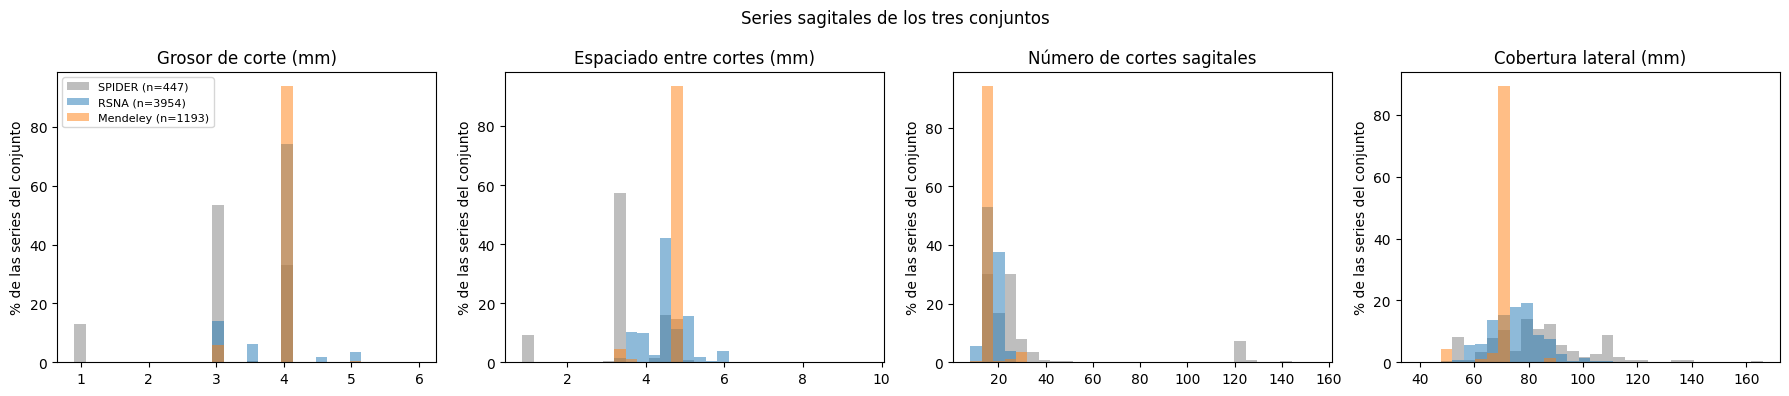

In [5]:
# 11. Comparación de las series sagitales con SPIDER
if "sag" not in globals():      # sin la sesión completa se leen los resúmenes que guardaron las celdas 7 y 9
    _r = pd.read_csv(DIR_PRIVADO_RSNA / "series_rsna.csv", dtype={"study_id": str, "series_id": str})
    sag = _r[(_r["particion"] == "train") & (_r["orientacion"] == "sagital")].assign(
        tipo=lambda d: d["series_description"].fillna("(sin descripción)"))
if "sag_m" not in globals():
    _m = pd.read_csv(DIR_SALIDA / "mendeley_inventario" / "series_mendeley.csv", dtype={"paciente": str})
    sag_m = _m[_m["orientacion"] == "sagital"].assign(tipo=lambda d: d["descripcion_dicom"].fillna("(sin descripción)"))
spider = pd.read_csv(CSV_INVENTARIO_01, dtype={"serie": str})
# En SPIDER el eje lateral no siempre es el primero de tamano_vox: es el que tiene el espaciado de espaciado_lr_mm
tam = spider["tamano_vox"].str.strip("()").str.split(",").map(lambda v: [float(x) for x in v])
esp = spider["espaciado_mm"].str.strip("()").str.split(",").map(lambda v: [float(x) for x in v])
eje_lr = [int(np.argmin([abs(e - lr) for e in es])) for es, lr in zip(esp, spider["espaciado_lr_mm"])]
spider["cortes"] = [t[i] for t, i in zip(tam, eje_lr)]
spider["cobertura_lateral_mm"] = spider["cortes"] * spider["espaciado_lr_mm"]
# En Mendeley solo cuentan las sagitales reales: fuera localizadores, PosDisp, reconstrucciones y series axiales o coronales
NO_SAGITAL_REAL = ("posdisp", "localizer", "mip", "mpr", "new series", "haste", "_cor", "_tra", "vessels")
desc_m = sag_m["tipo"].astype(str).str.lower()
sag_m_real = sag_m[desc_m.str.contains("sag") & ~desc_m.map(lambda t: any(p in t for p in NO_SAGITAL_REAL))]
print(f"Mendeley: {len(sag_m_real)} series sagitales reales de {len(sag_m)} clasificadas como sagitales")
comparables = pd.concat([
    pd.DataFrame({"conjunto": "SPIDER", "secuencia": spider["secuencia"], "grosor_mm": spider["SliceThickness"],
                  "espaciado_mm": spider["espaciado_lr_mm"], "cortes": spider["cortes"],
                  "cobertura_lateral_mm": spider["cobertura_lateral_mm"]}),
    pd.DataFrame({"conjunto": "RSNA", "secuencia": sag["tipo"], "grosor_mm": sag["grosor_mm"],
                  "espaciado_mm": sag["espaciado_real_mm"], "cortes": sag["n_imagenes"],
                  "cobertura_lateral_mm": sag["cobertura_normal_mm"]}),
    pd.DataFrame({"conjunto": "Mendeley", "secuencia": sag_m_real["tipo"], "grosor_mm": sag_m_real["grosor_mm"],
                  "espaciado_mm": sag_m_real["espaciado_real_mm"], "cortes": sag_m_real["n_imagenes"],
                  "cobertura_lateral_mm": sag_m_real["cobertura_normal_mm"]})], ignore_index=True)
MEDIDAS = ["grosor_mm", "espaciado_mm", "cortes", "cobertura_lateral_mm"]
for c in MEDIDAS:
    comparables[c] = pd.to_numeric(comparables[c], errors="coerce")
tabla_comp = comparables.groupby("conjunto")[MEDIDAS].describe(percentiles=[0.1, 0.5, 0.9]).round(2)
tabla_comp.to_csv(DIR_SALIDA / "comparacion_con_spider.csv")
display(comparables.groupby("conjunto")[MEDIDAS].median().round(2))
print("Percentiles 10 y 90 de la cobertura lateral (mm):")
print(comparables.groupby("conjunto")["cobertura_lateral_mm"].quantile([0.1, 0.9]).unstack().round(1).to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
TITULOS = ("Grosor de corte (mm)", "Espaciado entre cortes (mm)", "Número de cortes sagitales", "Cobertura lateral (mm)")
for ax, col, titulo in zip(axes, MEDIDAS, TITULOS):
    bordes = np.histogram_bin_edges(comparables[col].dropna(), bins=30)    # los mismos intervalos para los tres conjuntos
    for conjunto, color in (("SPIDER", "tab:gray"), ("RSNA", "tab:blue"), ("Mendeley", "tab:orange")):
        v = comparables.loc[comparables["conjunto"] == conjunto, col].dropna()
        if len(v):
            ax.hist(v, bins=bordes, alpha=0.5, color=color, label=f"{conjunto} (n={len(v)})",
                    weights=np.full(len(v), 100 / len(v)))
    ax.set_title(titulo)
    ax.set_ylabel("% de las series del conjunto")
axes[0].legend(fontsize=8)
fig.suptitle("Series sagitales de los tres conjuntos")
plt.tight_layout()
fig.savefig(DIR_SALIDA / "comparacion_con_spider.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer la tabla y la gráfica.** La tabla presenta la mediana de cada medida para los tres conjuntos y, a continuación, los percentiles 10 y 90 de la cobertura lateral. El archivo `comparacion_con_spider.csv` conserva también los demás percentiles. En la gráfica, cada color representa un conjunto. Los tres utilizan los mismos intervalos y la altura de las barras indica el porcentaje de series de cada conjunto, de modo que las distribuciones se pueden comparar aunque el número de series sea diferente.

**Resultados.** En la mediana, SPIDER tiene cortes de 3 mm, separados 3,31 mm, con 24 cortes sagitales y 82,3 mm de cobertura lateral. RSNA presenta cortes de 4 mm, separados 4,48 mm, con 17 cortes y 74,4 mm de cobertura. Mendeley también tiene cortes de 4 mm, pero separados 4,8 mm, con 15 cortes y 71,2 mm de cobertura. En conjunto, los dos conjuntos externos tienen cortes más gruesos y más separados, y un menor número de cortes que SPIDER.

En el cuaderno 04, el aumento del grosor redujo el ángulo en aproximadamente 0,25° con 3,3 mm y 0,38° con 4,4 mm. Por eso, al comparar los ángulos de RSNA y Mendeley con los de SPIDER, podría aparecer una pequeña tendencia a valores inferiores asociada a la adquisición, y no necesariamente a un error del segmentador. Esta diferencia debe tenerse en cuenta al interpretar los resultados.

La cobertura lateral mediana también es menor en los conjuntos externos, aunque el extremo inferior de RSNA es muy parecido al de SPIDER. El percentil 10 es de 62,7 mm en SPIDER y 62 mm en RSNA. En Mendeley, la cobertura es constante y vale 71,2 mm. Por tanto, las series más estrechas de RSNA no tienen una cobertura inferior a las más estrechas de SPIDER. Con estos datos no se anticipa un aumento marcado de discos cortados por los bordes, aunque esto deberá comprobarse con las marcas de calidad del cuaderno 09.

La diferencia más clara aparece en el extremo superior. En SPIDER, el 10 % de las series tiene una cobertura lateral de 108 mm o más, principalmente por las adquisiciones T2 SPACE. RSNA y Mendeley no presentan coberturas tan amplias.

## Conversión a NIfTI

TotalSpineSeg solo admite imágenes NIfTI, por lo que cada serie sagital debe convertirse antes de segmentarla. Hacer esta conversión en CPU permite identificar de antemano qué series se pueden procesar, evitar que la GPU pierda tiempo con series que fallan y comprobar cada volumen antes de enviarlo a Kaggle.

La celda 12 define el procedimiento en un bloque de código que también se guarda como `conversion08.py` entre las entradas de Kaggle. De esta manera, el cuaderno de Kaggle utiliza exactamente el mismo código para convertir RSNA. Para comprobar que el resultado es reproducible, de cada volumen se guarda una huella calculada a partir de sus vóxeles y su geometría. Esa huella debe coincidir al repetir la conversión en Colab y en Kaggle.

La conversión utiliza el lector de series de SimpleITK (GDCM), que ordena los cortes según su posición física. Para cada serie se registra cuántas series distintas encuentra GDCM en la carpeta, cuántos archivos utiliza respecto a los disponibles, el tamaño y el espaciado del volumen, el eje físico de los cortes, el número de cortes vacíos, los percentiles de intensidad y si la geometría se conserva al volver a leer el NIfTI. Se procesan todas las series clasificadas como sagitales en el inventario. Las que fallan quedan registradas con su error y no pasan a las listas de trabajo.

In [ ]:
# 12. Conversión a NIfTI: el mismo código que usará el cuaderno de Kaggle
CODIGO_CONVERSION = r"""
# Conversión de una serie DICOM a NIfTI con comprobaciones (cuaderno 08 en Colab y cuaderno auxiliar de Kaggle)
import hashlib
from pathlib import Path
import numpy as np
import SimpleITK as sitk

TOL_GEOMETRIA = 1e-3

def misma_geometria(a, b, tol=TOL_GEOMETRIA):
    'True si dos imágenes ocupan exactamente la misma rejilla en el espacio.'
    return (a.GetSize() == b.GetSize() and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=tol)
            and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=tol)
            and np.allclose(a.GetDirection(), b.GetDirection(), atol=tol))

def huella_volumen(img):
    'md5 de los vóxeles y de la geometría redondeada: igual en Colab y en Kaggle si la conversión es la misma.'
    h = hashlib.md5(np.ascontiguousarray(sitk.GetArrayViewFromImage(img)).tobytes())
    geometria = (img.GetSize(), tuple(round(v, 4) for v in img.GetSpacing()),
                 tuple(round(v, 3) for v in img.GetOrigin()), tuple(round(v, 5) for v in img.GetDirection()))
    h.update(repr(geometria).encode())
    return h.hexdigest()

def leer_serie(carpeta):
    'Lee con GDCM la serie DICOM de una carpeta; si hay varias, la de más archivos.'
    lector = sitk.ImageSeriesReader()
    ids = lector.GetGDCMSeriesIDs(str(carpeta))
    if not ids:
        raise RuntimeError('GDCM no encontró ninguna serie en la carpeta')
    archivos = max((lector.GetGDCMSeriesFileNames(str(carpeta), i) for i in ids), key=len)
    lector.SetFileNames(archivos)
    return lector.Execute(), len(ids), len(archivos)

def convertir(carpeta, destino):
    'Convierte la serie DICOM de una carpeta a NIfTI comprimido y devuelve las comprobaciones.'
    img, n_ids, n_usados = leer_serie(carpeta)
    n_total = sum(1 for p in Path(carpeta).iterdir() if p.is_file())
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    sitk.WriteImage(img, str(destino), useCompression=True)
    releida = sitk.ReadImage(str(destino))
    arr = sitk.GetArrayViewFromImage(img)
    plano = arr.reshape(arr.shape[0], -1)
    D = np.array(img.GetDirection()).reshape(3, 3)
    eje_cortes = int(np.argmax(np.abs(D[:, 2])))     # componente física dominante del eje de los cortes
    p1, p50, p99 = np.percentile(arr, [1, 50, 99])
    return {'series_en_carpeta': n_ids, 'archivos': n_total, 'archivos_usados': n_usados,
            'tamano': 'x'.join(map(str, img.GetSize())), 'espaciado': 'x'.join(f'{v:.3f}' for v in img.GetSpacing()),
            'cortes': img.GetSize()[2], 'eje_de_cortes': ('LR', 'AP', 'SI')[eje_cortes],
            'cortes_vacios': int((plano.max(axis=1) == plano.min(axis=1)).sum()),
            'p1': float(p1), 'p50': float(p50), 'p99': float(p99),
            'geometria_nifti_ok': bool(misma_geometria(img, releida)),
            'huella_volumen': huella_volumen(img), 'bytes_nifti': destino.stat().st_size}
"""
exec(CODIGO_CONVERSION)

def anotar(csv, fila):
    "Agrega una fila al registro de la corrida."
    pd.DataFrame([fila]).to_csv(csv, mode="a", header=not csv.exists(), index=False)

def copiar_seguro(origen, destino):
    "Copia a Drive con nombre temporal y renombra al final: si Colab se corta, no queda un archivo a medias."
    destino.parent.mkdir(parents=True, exist_ok=True)
    tmp = destino.with_name(destino.name + ".tmp")
    shutil.copy(origen, tmp)
    os.replace(tmp, destino)

In [ ]:
# 13. Conversión de todas las series sagitales (retoma donde iba)
import SimpleITK as sitk
DIR_NIFTI = {"mendeley": DIR_DATOS / "mendeley" / "nifti_sagital", "rsna": DIR_DATOS / "rsna" / "nifti_sagital"}
CSV_CONV = {"mendeley": DIR_SALIDA / "conversion_mendeley.csv", "rsna": DIR_PRIVADO_RSNA / "conversion_rsna.csv"}
ZIP_LOCAL = {"mendeley": LOCAL_MENDELEY, "rsna": LOCAL_RSNA}
DIR_TMP = DIR_LOCAL / "serie_tmp"

# Una fila por serie sagital: identificador, estudio, tipo y rutas de sus imágenes dentro del zip
filas = []
dic_m = dicom_m.merge(series_m[["paciente", "serie_clave", "orientacion", "descripcion_dicom"]], on=["paciente", "serie_clave"])
dic_m["SeriesNumber_n"] = pd.to_numeric(dic_m["SeriesNumber"], errors="coerce")
for pac, g in dic_m[dic_m["orientacion"] == "sagital"].groupby("paciente"):
    orden = g.groupby("serie_clave")["SeriesNumber_n"].min().sort_values(kind="stable").index
    for k, clave in enumerate(orden, 1):
        gg = g[g["serie_clave"] == clave]
        filas.append({"conjunto": "mendeley", "id_serie": f"men_{pac}_{k}", "estudio": str(pac), "serie_clave": clave,
                      "tipo": gg["descripcion_dicom"].iloc[0], "rutas": gg["archivo"].tolist()})
img_r = imagenes_rsna[(imagenes_rsna["es_dicom"] == "True") & (imagenes_rsna["particion"] == "train")]
tipos_r = sag.set_index(["study_id", "series_id"])["tipo"]
for (st, se), g in img_r.groupby(["study_id", "series_id"]):
    if (st, se) in tipos_r.index:
        filas.append({"conjunto": "rsna", "id_serie": f"rsna_{st}_{se}", "estudio": st, "serie_clave": se,
                      "tipo": tipos_r.loc[(st, se)], "rutas": g["archivo"].tolist()})
sagitales = pd.DataFrame(filas)
assert sagitales["id_serie"].is_unique
print(sagitales.groupby("conjunto").agg(series=("id_serie", "size"), estudios=("estudio", "nunique")).to_string())

def convertir_desde_zip(z, rutas, destino):
    "Extrae las imágenes de una serie a una carpeta temporal y la convierte."
    shutil.rmtree(DIR_TMP, ignore_errors=True)
    DIR_TMP.mkdir(parents=True)
    for k, ruta in enumerate(rutas):
        (DIR_TMP / f"{k:05d}_{ruta.rsplit('/', 1)[-1]}").write_bytes(z.read(ruta))
    return convertir(DIR_TMP, destino)

for conjunto in ("mendeley", "rsna"):
    hechas = set()
    if CSV_CONV[conjunto].exists():
        reg = pd.read_csv(CSV_CONV[conjunto], dtype=str)
        hechas = set(reg.loc[reg["estado"] == "ok", "id_serie"])
    pendientes = sagitales[(sagitales["conjunto"] == conjunto) & ~sagitales["id_serie"].isin(hechas)]
    print(f"{conjunto}: {len(hechas)} convertidas antes | {len(pendientes)} pendientes")
    inicio = time.time()
    with zipfile.ZipFile(ZIP_LOCAL[conjunto]) as z:
        for k, r in enumerate(pendientes.itertuples(), 1):
            local = DIR_LOCAL / "nifti" / conjunto / f"{r.id_serie}.nii.gz"
            fila = {"conjunto": conjunto, "id_serie": r.id_serie, "estudio": r.estudio, "serie_clave": r.serie_clave,
                    "tipo": r.tipo, "imagenes_inventario": len(r.rutas)}
            try:
                fila.update(convertir_desde_zip(z, r.rutas, local))
                copiar_seguro(local, DIR_NIFTI[conjunto] / local.name)
                local.unlink()
                fila["estado"] = "ok"
            except Exception as e:
                fila.update({"estado": "error", "error": f"{type(e).__name__}: {e}"[:300]})
            anotar(CSV_CONV[conjunto], fila)
            if k % 200 == 0 or fila["estado"] != "ok":
                error_pub = fila.get('error', '') if conjunto == 'mendeley' else re.sub(r'\d{4,}', '<id>', fila.get('error', ''))
                print(f"  [{k}/{len(pendientes)}] {r.id_serie if conjunto == 'mendeley' else 'serie de RSNA'}: "
                      f"{fila['estado']} {error_pub} | {(time.time() - inicio) / 60:.0f} min")
print("Listo. Las filas repetidas por una retoma se descartan al leer los registros.")

          series  estudios
conjunto                  
mendeley    1532       515
rsna        3954      1975
mendeley: 0 convertidas antes | 1532 pendientes
  [7/1532] men_0003_3: error RuntimeError: Exception thrown in SimpleITK ImageSeriesReader_Execute: /tmp/SimpleITK-build/ITK-prefix/include/ITK-5.4/itkImageFileReader.hxx:338:
ImageIO returns IO region that does not fully contain the requested region. Requested region: ImageRegion (0x7ffe79790b70)
  Dimension: 3
  Index: [0, 0, | 0 min
  [10/1532] men_0004_3: error RuntimeError: Exception thrown in SimpleITK ImageSeriesReader_Execute: /tmp/SimpleITK-build/ITK-prefix/include/ITK-5.4/itkImageSeriesReader.hxx:351:
ITK ERROR: ImageSeriesReader(0x72676d0): Size mismatch! The size of  /content/datos08/serie_tmp/00000_POSDISP_[4]_0004_001.ima is [512, 512, 1] and doe | 0 min
  [13/1532] men_0005_3: error RuntimeError: Exception thrown in SimpleITK ImageSeriesReader_Execute: /tmp/SimpleITK-build/ITK-prefix/include/ITK-5.4/itkImageSeriesRead

In [ ]:
# 14. Resumen de la conversión y selección de una T1 y una T2 sagitales por estudio
import csv
COLUMNAS_BASE = ["conjunto", "id_serie", "estudio", "serie_clave", "tipo", "imagenes_inventario"]
COLUMNAS_CONV = ["series_en_carpeta", "archivos", "archivos_usados", "tamano", "espaciado", "cortes", "eje_de_cortes",
                 "cortes_vacios", "p1", "p50", "p99", "geometria_nifti_ok", "huella_volumen", "bytes_nifti"]

def leer_registro(ruta):
    "Lee el registro de conversión aunque las filas de error tengan menos columnas que las convertidas."
    filas = []
    with open(ruta, newline="", encoding="utf-8") as f:
        for r in csv.reader(f):
            if not r or r[0] == "conjunto":
                continue
            if len(r) == len(COLUMNAS_BASE) + len(COLUMNAS_CONV) + 1:
                filas.append(dict(zip(COLUMNAS_BASE + COLUMNAS_CONV + ["estado"], r)))
            elif len(r) == len(COLUMNAS_BASE) + 2:
                filas.append(dict(zip(COLUMNAS_BASE + ["estado", "error"], r)))
            else:
                raise ValueError(f"Fila con {len(r)} campos en {ruta}")
    d = pd.DataFrame(filas)
    for c in ("imagenes_inventario", "series_en_carpeta", "archivos", "archivos_usados", "cortes", "cortes_vacios",
              "p1", "p50", "p99", "bytes_nifti"):
        d[c] = pd.to_numeric(d.get(c), errors="coerce")
    return d.drop_duplicates("id_serie", keep="last")

conversion = pd.concat([leer_registro(CSV_CONV[c]) for c in ("mendeley", "rsna")], ignore_index=True)
ok = conversion["estado"] == "ok"
avisos = pd.DataFrame({
    "error": ~ok,
    "varias_series_en_carpeta": ok & (conversion["series_en_carpeta"] > 1),
    "archivos_sin_usar": ok & (conversion["archivos_usados"] < conversion["archivos"]),
    "cortes_no_laterales": ok & (conversion["eje_de_cortes"] != "LR"),
    "cortes_vacios": ok & (conversion["cortes_vacios"] > 0),
    "geometria_nifti_distinta": ok & (conversion["geometria_nifti_ok"] != "True"),
})
resumen_conv = pd.concat([conversion[["conjunto"]], avisos], axis=1).groupby("conjunto").sum()
resumen_conv.insert(0, "series", conversion.groupby("conjunto").size())
resumen_conv.insert(1, "convertidas", conversion[ok].groupby("conjunto").size())
display(resumen_conv)
resumen_conv.to_csv(DIR_SALIDA / "conversion_resumen.csv")
if (~ok).any():
    print("Errores por tipo de serie (los más frecuentes):")
    print(conversion.loc[~ok, "tipo"].value_counts().head(15).to_string())
    print("Errores más frecuentes:")
    errores_pub = conversion.loc[~ok].apply(lambda f: str(f["error"]) if f["conjunto"] == "mendeley"
                                            else re.sub(r"\d{4,}", "<id>", str(f["error"])), axis=1)
    print(errores_pub.str.slice(0, 90).value_counts().head(5).to_string())

# Selección: una T1 y una T2 (o STIR) sagitales por estudio, como se decidió para la segmentación.
# En RSNA el tipo viene de train_series_descriptions.csv; en Mendeley, de la descripción DICOM, y se descartan
# localizadores, reconstrucciones (MIP, MPR, PosDisp), series coronales o axiales y densidad protónica.
DESCARTE_MENDELEY = ("posdisp", "localizer", "mip", "mpr", "new series", "haste", "_cor", "_tra", "vessels", "pd_")

def clase_serie(conjunto, tipo):
    t = str(tipo).lower()
    if conjunto == "rsna":
        return {"sagittal t1": "T1", "sagittal t2/stir": "T2"}.get(t, "otra")
    if "sag" not in t or any(p in t for p in DESCARTE_MENDELEY):
        return "otra"
    if "t1" in t:
        return "T1"
    if "t2" in t or "tirm" in t or "stir" in t:
        return "T2"
    return "otra"

def con_contraste(tipo):
    return any(p in str(tipo).lower() for p in ("contrast", "contast", "_cm", "+ c"))

def con_supresion_grasa(tipo):
    return any(p in str(tipo).lower() for p in ("_fs", "-fs", "fatsat", "tirm", "stir"))

seleccion = conversion[ok].copy()
seleccion["clase"] = [clase_serie(c, t) for c, t in zip(seleccion["conjunto"], seleccion["tipo"])]
seleccion["contraste"] = seleccion["tipo"].map(con_contraste)
seleccion["supresion_grasa"] = seleccion["tipo"].map(con_supresion_grasa) & (seleccion["conjunto"] == "mendeley")
seleccion = seleccion[(seleccion["clase"] != "otra") & (seleccion["eje_de_cortes"] == "LR")]
# Preferencia dentro de cada estudio y clase: sin contraste, sin supresión grasa, más cortes y luego el identificador
seleccion = seleccion.sort_values(["conjunto", "estudio", "clase", "contraste", "supresion_grasa", "cortes", "id_serie"],
                                  ascending=[True, True, True, True, True, False, True])
seleccion["seleccionada"] = ~seleccion.duplicated(["conjunto", "estudio", "clase"])
cols = ["conjunto", "id_serie", "estudio", "tipo", "clase", "contraste", "supresion_grasa", "cortes", "seleccionada"]
seleccion.loc[seleccion["conjunto"] == "mendeley", cols].to_csv(DIR_SALIDA / "seleccion_mendeley.csv", index=False)
seleccion.loc[seleccion["conjunto"] == "rsna", cols].to_csv(DIR_PRIVADO_RSNA / "seleccion_rsna.csv", index=False)

elegidas = seleccion[seleccion["seleccionada"]]
por_estudio = elegidas.groupby(["conjunto", "estudio"])["clase"].agg(lambda s: "".join(sorted(s)))
resumen_sel = pd.DataFrame({
    "series_convertidas": conversion[ok].groupby("conjunto").size(),
    "candidatas_T1_o_T2": seleccion.groupby("conjunto").size(),
    "seleccionadas": elegidas.groupby("conjunto").size(),
    "estudios": por_estudio.groupby("conjunto").size(),
    "estudios_con_T1_y_T2": (por_estudio == "T1T2").groupby("conjunto").sum(),
    "seleccionadas_con_contraste": elegidas.groupby("conjunto")["contraste"].sum(),
})
display(resumen_sel)
resumen_sel.to_csv(DIR_SALIDA / "seleccion_resumen.csv")
print("Tipos de serie elegidos en Mendeley:")
print(elegidas.loc[elegidas["conjunto"] == "mendeley", "tipo"].value_counts().to_string())
print(f"\nNIfTI de Mendeley: {conversion.loc[ok & (conversion['conjunto'] == 'mendeley'), 'bytes_nifti'].sum() / 1e9:.2f} GB | "
      f"de RSNA: {conversion.loc[ok & (conversion['conjunto'] == 'rsna'), 'bytes_nifti'].sum() / 1e9:.2f} GB")

,series,convertidas,error,varias_series_en_carpeta,archivos_sin_usar,cortes_no_laterales,cortes_vacios,geometria_nifti_distinta
conjunto,,,,,,,,
mendeley,1532,1221,311,0,0,0,0,0
rsna,3954,3954,0,0,0,0,0,0


Errores por tipo de serie (los más frecuentes):
tipo
PosDisp: [4] t2_tse_tra_384       211
PosDisp: [5] t1_tse_tra            26
PosDisp: [5] t2_tse_tra_384        25
PosDisp: [6] t2_tse_tra_384        10
PosDisp: [4] t2_me2d_tra_p2         8
PosDisp: [6] t1_tse_tra             4
PosDisp: [6] t2_me2d_tra_p2         3
PosDisp: [6] t2_tse_tra_BOX         2
PosDisp: [7] t2_tse_tra_BOX         2
PosDisp: [5] t2_me2d_tra_p2         2
PosDisp: [7] t1_tse_tra             2
PosDisp: [7] t2_tse_tra_384         2
<MIP Range>                         2
PosDisp: [7] t1_tse_tra-FS-BOX      1
<MPR Range>                         1
Errores más frecuentes:
error
RuntimeError: Exception thrown in SimpleITK ImageSeriesReader_Execute: /tmp/SimpleITK-buil    311


,series_convertidas,candidatas_T1_o_T2,seleccionadas,estudios,estudios_con_T1_y_T2,seleccionadas_con_contraste
conjunto,,,,,,
mendeley,1221,1185,1030,515,515,0
rsna,3954,3954,3947,1975,1972,0


Tipos de serie elegidos en Mendeley:
tipo
t2_tse_sag_384         504
t1_tse_sag_320         497
t1_tse_sag_384          17
t2_tse_sag_448           5
t2_tse_SAG_380           2
t2_tse_sag_256           2
I_t1_tse_sag_p2          1
I_t2_tse_sag_p2_384      1
t2_tse_sag_320           1

NIfTI de Mendeley: 2.82 GB | de RSNA: 17.22 GB


**Cómo leer la salida de las celdas 13 y 14.** La celda 13 informa cuántas series sagitales y cuántos estudios hay en cada conjunto, además de señalar las series que presentan errores durante la conversión. Los identificadores de las series de RSNA se omiten en la salida pública. La primera tabla de la celda 14 resume, por conjunto, cuántas series se procesaron, cuántas se convirtieron y cuántas presentaron algún aviso. Un aviso no impide necesariamente la segmentación, pero debe tenerse en cuenta al interpretar el resultado.

Después, la celda selecciona una T1 y una T2 sagitales por estudio, que son las secuencias elegidas para segmentar. En RSNA, el tipo de serie se obtiene de `train_series_descriptions.csv`; en Mendeley, de la descripción DICOM. Se descartan localizadores, reconstrucciones, adquisiciones de densidad protónica y series axiales o coronales. Si hay varias candidatas, se prioriza la que no tiene contraste, después la que no tiene supresión grasa y, por último, la que tiene más cortes. La segunda tabla muestra cuántas series eran candidatas, cuántas se seleccionaron y en cuántos estudios quedó disponible una serie de cada tipo.

**Resultados.** En RSNA se convirtieron 3.954 series sagitales sin errores ni avisos, en algo menos de dos horas. En Mendeley se convirtieron 1.221 de las 1.532 series clasificadas como sagitales. Las 311 restantes fallaron durante la lectura. Los errores se concentran en series que no corresponden a adquisiciones sagitales reales, principalmente imágenes `PosDisp` y algunas reconstrucciones MIP y MPR. En varios casos, el lector encontró imágenes de distintos tamaños dentro de una misma serie. Ninguna adquisición sagital T1 o T2 real falló. Las 1.185 candidatas de la selección son exactamente las 1.193 sagitales reales que cuenta la celda 11, menos las 8 de densidad protónica. Entre las series convertidas tampoco se detectaron varias series en una misma carpeta, archivos sin utilizar, cortes fuera del eje lateral, cortes vacíos ni diferencias de geometría al volver a leer el NIfTI.

Para la selección final, Mendeley tenía 1.185 series candidatas y se eligieron 1.030, exactamente una T1 y una T2 para cada uno de los 515 pacientes. Las más frecuentes fueron `t2_tse_sag_384` (504) y `t1_tse_sag_320` (497). Ninguna de las series seleccionadas tiene contraste y ninguna T2 es STIR, porque se priorizó la secuencia sin supresión grasa.

En RSNA se eligieron 3.947 de las 3.954 series convertidas. La diferencia corresponde a siete estudios que tenían dos T1 sagitales, de los cuales se conservó una. En total, 1.972 estudios tienen una T1 y una T2. A diferencia de Mendeley, en RSNA la secuencia T2 puede ser T2 o STIR, porque la tabla de la competición las agrupa como “Sagittal T2/STIR” y no permite separarlas por nombre. Los NIfTI ocupan 2,82 GB en Mendeley considerando todas las series convertidas y 17,22 GB en RSNA.

## Listas de trabajo

Las series seleccionadas en la celda 14 fueron una T1 y una T2 sagitales por estudio se distribuyen entre dos cuentas de Kaggle. La asignación se hace por estudio, de modo que las dos secuencias de un mismo paciente siempre quedan en la misma lista.

En cada conjunto, los estudios se ordenan por identificador y se mezclan con la semilla 2026. La primera mitad forma la lista A. La otra mitad se vuelve a mezclar con la semilla 2027 para formar la lista B. Así se evita que un estudio aparezca en las dos cuentas. Además, como cada lista se procesa en orden aleatorio, si la segmentación se interrumpe antes de terminar, los estudios procesados hasta ese momento siguen formando una muestra aleatoria del conjunto.

Cada lista contiene primero el bloque de Mendeley y después el de RSNA, ya que Mendeley es el conjunto que incluye notas de radiólogos. La celda 15 guarda las listas en una carpeta privada porque contienen identificadores de estudios de RSNA. También estima el tiempo de GPU a partir de los 35 segundos por serie medidos en el cuaderno 05 con la GPU de Colab. El tiempo real en Kaggle puede ser diferente.

In [6]:
# 15. Listas A y B (solo las series seleccionadas: una T1 y una T2 por estudio)
SEMILLA_A, SEMILLA_B = 2026, 2027
SEGUNDOS_POR_SERIE_GPU = 35          # TotalSpineSeg en la GPU de Colab, cuaderno 05 (lotes de 20 series)
DIR_LISTAS = DIR_DATOS / "segmentacion_08" / "listas"        # privado: contiene identificadores de RSNA
DIR_LISTAS.mkdir(parents=True, exist_ok=True)
RUTAS_LISTAS = {l: DIR_LISTAS / f"lista_{l}.csv" for l in "AB"}
ya_guardadas = all(r.exists() for r in RUTAS_LISTAS.values())

def repartir(estudios):
    "Lista A: primera mitad de los estudios barajados con la semilla A. Lista B: el resto, barajado con la semilla B."
    estudios = sorted(estudios)
    orden = [estudios[i] for i in np.random.default_rng(SEMILLA_A).permutation(len(estudios))]
    mitad = (len(orden) + 1) // 2
    resto = sorted(orden[mitad:])
    return orden[:mitad], [resto[i] for i in np.random.default_rng(SEMILLA_B).permutation(len(resto))]

def leer_listas():
    return pd.concat([pd.read_csv(RUTAS_LISTAS[l], dtype={"estudio": str, "serie_clave": str}) for l in "AB"],
                     ignore_index=True)

if "elegidas" in globals():
    filas = []
    for bloque, conjunto in enumerate(("mendeley", "rsna"), 1):
        c = elegidas[elegidas["conjunto"] == conjunto]
        for lista, estudios in zip("AB", repartir(c["estudio"].unique())):
            for orden_estudio, est in enumerate(estudios, 1):
                for r in c[c["estudio"] == est].sort_values("clase").itertuples():
                    filas.append({"lista": lista, "bloque": bloque, "conjunto": conjunto, "orden_estudio": orden_estudio,
                                  "estudio": est, "id_serie": r.id_serie, "serie_clave": r.serie_clave, "clase": r.clase,
                                  "tipo": r.tipo, "huella_volumen": r.huella_volumen})
    listas = pd.DataFrame(filas)
    listas["orden"] = listas.groupby("lista").cumcount() + 1
    assert not listas.duplicated("id_serie").any()
    assert not (set(listas.loc[listas["lista"] == "A", "estudio"]) & set(listas.loc[listas["lista"] == "B", "estudio"]))
    if ya_guardadas:
        # Kaggle ya usa las listas guardadas: no se reescriben, solo se comprueba que salgan idénticas
        clave = ["lista", "orden", "id_serie", "huella_volumen"]
        nuevas, previas = (d[clave].astype(str).sort_values(["lista", "orden"]).reset_index(drop=True)
                           for d in (listas, leer_listas()))
        assert nuevas.equals(previas), "Las listas regeneradas NO coinciden con las guardadas: no seguir y revisar"
        print("Las listas regeneradas coinciden con las guardadas, que no se tocan.")
    else:
        for lista in "AB":
            listas[listas["lista"] == lista].to_csv(RUTAS_LISTAS[lista], index=False)
else:
    assert ya_guardadas, "No hay listas guardadas ni selección de la celda 14: corre antes las celdas 12, 13 y 14"
    listas = leer_listas()
    print("Se leen las listas guardadas, que son las que usa Kaggle (para regenerarlas hay que correr antes la celda 14).")

resumen_listas = listas.groupby(["lista", "conjunto"]).agg(estudios=("estudio", "nunique"), series=("id_serie", "size"))
resumen_listas["horas_gpu_estimadas"] = (resumen_listas["series"] * SEGUNDOS_POR_SERIE_GPU / 3600).round(1)
display(resumen_listas)
resumen_listas.to_csv(DIR_SALIDA / "listas_resumen.csv")
print("Horas de GPU estimadas por lista:", resumen_listas.groupby("lista")["horas_gpu_estimadas"].sum().to_dict())

Se leen las listas guardadas, que son las que usa Kaggle (para regenerarlas hay que correr antes la celda 14).


estudios  series  horas_gpu_estimadas
lista conjunto                                       
A     mendeley       258     516                  5.0
      rsna           988    1975                 19.2
B     mendeley       257     514                  5.0
      rsna           987    1972                 19.2

Horas de GPU estimadas por lista: {'A': 24.2, 'B': 24.2}


**Resultados.** La lista A contiene 258 pacientes de Mendeley (516 series) y 988 estudios de RSNA (1.975 series), para un total de 2.491 series. La lista B contiene 257 pacientes de Mendeley (514 series) y 987 estudios de RSNA (1.972 series), con un total de 2.486 series. Ningún estudio aparece en ambas listas.

Con el tiempo de referencia de 35 segundos por serie medido en el cuaderno 05, cada lista requeriría unas 24 horas de GPU. Sin embargo, Kaggle utiliza dos GPU T4 en paralelo. En los primeros lotes de la lista A, cada GPU tardó alrededor de 23 segundos por serie. Con ese rendimiento, una lista completa cabe en una sola sesión de unas 8 a 9 horas. La duración real de cada lista se reporta en el cuaderno 09, junto con la revisión de las máscaras que produjo Kaggle.

## Prueba de TotalSpineSeg en CPU

Antes de dedicar horas de GPU al procesamiento completo, se quiso comprobar si la cadena de segmentación podía ejecutarse con estas series. La celda 16 instala TotalSpineSeg en un entorno independiente, con la misma versión y los mismos pesos utilizados en el cuaderno 05. Ambos se verifican mediante sus huellas. La celda 17 intenta ejecutar el segmentador en CPU sobre las dos primeras series de la lista A de cada conjunto.

Para cada serie, el procedimiento mide el tiempo de ejecución, comprueba si la máscara conserva la geometría de la imagen, traduce las etiquetas a la convención de SPIDER y, si logra terminar, dibuja un corte sagital con las vértebras rotuladas. En esa numeración, V1 es la vértebra más caudal, como en SPIDER; entre paréntesis se indica el nivel anatómico asignado por TotalSpineSeg.

La prueba también busca responder si TotalSpineSeg podría ejecutarse en un computador sin GPU, algo relevante para el programa final. Las figuras de Mendeley se guardarían en la carpeta pública, mientras que las de RSNA permanecerían en la carpeta privada porque muestran imágenes del conjunto.

In [ ]:
# 16. Entorno aparte para TotalSpineSeg y pesos verificados (igual que en el cuaderno 05)
import subprocess, requests
VERSION_TSS = "20260807"
RELEASE_PESOS_TSS = "r20260730"
SHA256_PESOS_TSS = {
    "Dataset101_TotalSpineSeg_step1_r20260730.zip": "781f81e8c94feccd3cef17d819ba5c293b506e9b1f2b106fc5e31b9dd85887b0",
    "Dataset102_TotalSpineSeg_step2_r20260730.zip": "494c640ab8cb25475bd0fc4338c0931d37079af9dd19403879335c3908c06b46",
}
VENV_TSS = Path("/content/venv_tss")
DIR_TSS_DATOS = Path("/content/tss_datos")

def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

if not (VENV_TSS / "bin" / "totalspineseg").exists():
    subprocess.run("pip -q install virtualenv && virtualenv -q --system-site-packages /content/venv_tss", shell=True, check=True)
    subprocess.run([str(VENV_TSS / "bin" / "pip"), "-q", "install", f"totalspineseg=={VERSION_TSS}", "nnunetv2==2.6.2",
                    "kornia==0.8.2"], check=True)
os.environ["TOTALSPINESEG_DATA"] = str(DIR_TSS_DATOS)
dir_exports = DIR_TSS_DATOS / "nnUNet" / "exports"
dir_exports.mkdir(parents=True, exist_ok=True)
for nombre, sha_esperado in SHA256_PESOS_TSS.items():
    destino = dir_exports / nombre
    if not destino.exists():
        url = f"https://github.com/neuropoly/totalspineseg/releases/download/{RELEASE_PESOS_TSS}/{nombre}"
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(destino, "wb") as f:
                for trozo in r.iter_content(1 << 20):
                    f.write(trozo)
    assert sha256_archivo(destino) == sha_esperado, f"{nombre} NO coincide con la huella verificada; no continuar."
subprocess.run([str(VENV_TSS / "bin" / "totalspineseg_init"), "--quiet"], check=True, env=os.environ.copy())
print("TotalSpineSeg", VERSION_TSS, "con pesos", RELEASE_PESOS_TSS, "listo")

TotalSpineSeg 20260807 con pesos r20260730 listo


In [ ]:
# 17. TotalSpineSeg en CPU sobre las dos primeras series de la lista A de cada conjunto
# En Colab (2 núcleos) se detuvo en los cuatro intentos hacia los 7 minutos; ver la nota de abajo antes de activarla.
EJECUTAR_PRUEBA_CPU = False
from scipy import ndimage
import threading, queue, signal
N_PRUEBA_POR_CONJUNTO = 2
MINUTOS_MAXIMOS_POR_SERIE = 30      # en CPU; si se pasa, se detiene TotalSpineSeg y se sigue con la siguiente serie
NOMBRE_TSS = {**{11 + i: f"C{i + 1}" for i in range(7)}, **{21 + i: f"T{i + 1}" for i in range(12)},
              **{41 + i: f"L{i + 1}" for i in range(5)}, 50: "sacro"}

def etiquetas_y_alturas(mascara):
    "Etiquetas presentes y altura física (mm) del centroide de cada una; en LPS, +z es craneal."
    arr = sitk.GetArrayViewFromImage(mascara)
    etiquetas = [int(l) for l in np.unique(arr) if l != 0]
    centros = ndimage.center_of_mass(np.ones(arr.shape, dtype=np.uint8), labels=arr, index=etiquetas)
    return etiquetas, {l: mascara.TransformContinuousIndexToPhysicalPoint(tuple(float(v) for v in c[::-1]))[2]
                       for l, c in zip(etiquetas, centros)}

def traducir_tss_a_spider(mascara):
    "Como en el cuaderno 05: vértebras 1, 2, ... y discos 201, 202, ... de caudal a craneal; canal y médula = 100; sacro fuera."
    arr = sitk.GetArrayFromImage(mascara)
    etiquetas, alturas = etiquetas_y_alturas(mascara)
    tipo = {l: "disco" if 60 <= l <= 100 else "canal" if l in (1, 2) else "sacro" if l == 50 else "vertebra" for l in etiquetas}
    lut = {l: 100 for l in etiquetas if tipo[l] == "canal"}
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "vertebra"), key=alturas.get), 1)})
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "disco"), key=alturas.get), 201)})
    salida = np.zeros(arr.shape, dtype=np.uint16)
    for l, nueva in lut.items():
        salida[arr == l] = nueva
    traducida = sitk.GetImageFromArray(salida)
    traducida.CopyInformation(mascara)
    return traducida, {nueva: l for l, nueva in lut.items()}

def corte_sagital(imagen, arr):
    "Corte sagital central (filas: craneocaudal, columnas: anteroposterior), para dibujar con origin='lower'."
    D = np.array(imagen.GetDirection()).reshape(3, 3)
    i_lr, i_ap, i_si = (int(np.argmax(np.abs(D[k, :]))) for k in range(3))
    ax_lr, ax_ap, ax_si = 2 - i_lr, 2 - i_ap, 2 - i_si
    corte = np.take(arr, arr.shape[ax_lr] // 2, axis=ax_lr)
    restantes = [a for a in range(3) if a != ax_lr]
    corte = np.transpose(corte, (restantes.index(ax_si), restantes.index(ax_ap)))
    if D[2, i_si] < 0:
        corte = corte[::-1, :]
    esp = imagen.GetSpacing()
    return corte, esp[i_si] / esp[i_ap]

if not EJECUTAR_PRUEBA_CPU:
    print("Prueba en CPU desactivada (EJECUTAR_PRUEBA_CPU = False). Lo que se alcanzó a medir está en la nota de abajo.")
else:
    prueba = listas[listas["lista"] == "A"].groupby("conjunto").head(N_PRUEBA_POR_CONJUNTO)
    DIR_PRUEBA = DIR_LOCAL / "prueba_tss_cpu"
    filas_t = []
    prueba = prueba.assign(n_en_conjunto=prueba.groupby("conjunto").cumcount() + 1)
    for r in prueba.itertuples():
        entrada = DIR_NIFTI[r.conjunto] / f"{r.id_serie}.nii.gz"
        nombre_publico = r.id_serie if r.conjunto == "mendeley" else f"rsna_prueba_{r.n_en_conjunto}"
        ocultar = (lambda t: t) if r.conjunto == "mendeley" else (lambda t, s=r.id_serie, p=nombre_publico: t.replace(s, p))
        dir_out = DIR_PRUEBA / r.id_serie
        shutil.rmtree(dir_out, ignore_errors=True)
        cmd = [str(VENV_TSS / "bin" / "totalspineseg"), str(entrada), str(dir_out), "--device", "cpu",
               "--keep-only", "step2_output"]
        print(f"--- {r.id_serie if r.conjunto == 'mendeley' else 'serie de RSNA'}: empieza TotalSpineSeg en CPU "
              f"({os.cpu_count()} núcleos)", flush=True)
        t0 = time.time()
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                                env={**os.environ, "MPLBACKEND": "Agg"}, start_new_session=True)
        lineas = queue.Queue()
        threading.Thread(target=lambda: [lineas.put(l) for l in proc.stdout], daemon=True).start()
        ultimas, cortada = [], False
        while proc.poll() is None or not lineas.empty():   # muestra el avance mientras TotalSpineSeg trabaja
            try:
                linea = lineas.get(timeout=5).rstrip()
            except queue.Empty:
                linea = ""
            if linea:
                ultimas = (ultimas + [linea])[-20:]
                print(f"    [{(time.time() - t0) / 60:5.1f} min] {ocultar(linea)[:150]}", flush=True)
            if time.time() - t0 > MINUTOS_MAXIMOS_POR_SERIE * 60:      # se revisa aunque no llegue ninguna línea
                os.killpg(proc.pid, signal.SIGKILL)       # también los procesos que TotalSpineSeg lanzó por debajo
                cortada = True
                print(f"    Detenida a los {MINUTOS_MAXIMOS_POR_SERIE} min sin terminar", flush=True)
                break
        proc.wait()
        dt = time.time() - t0
        res = subprocess.CompletedProcess(cmd, proc.returncode, "", "\n".join(ultimas))
        salidas = sorted((dir_out / "step2_output").glob("*.nii.gz"))
        nombre_publico = r.id_serie if r.conjunto == "mendeley" else f"rsna_prueba_{r.n_en_conjunto}"
        fila = {"conjunto": r.conjunto, "serie": nombre_publico, "tipo": r.tipo, "segundos_cpu": round(dt, 1),
                "codigo_salida": res.returncode, "nucleos_cpu": os.cpu_count(), "detenida_por_tiempo": cortada}
        if res.returncode != 0 or len(salidas) != 1:
            print(ocultar(res.stderr[-2000:]))
            filas_t.append({**fila, "estado": "detenida" if cortada else "error"})
            continue
        img, seg = sitk.ReadImage(str(entrada)), sitk.ReadImage(str(salidas[0]))
        fila["geometria_ok"] = bool(misma_geometria(img, seg))
        if fila["geometria_ok"]:
            seg.CopyInformation(img)
        traducida, origen = traducir_tss_a_spider(seg)
        arr_t = sitk.GetArrayFromImage(traducida)
        vertebras = sorted(l for l in np.unique(arr_t) if 0 < l < 100)
        discos = sorted(l for l in np.unique(arr_t) if l > 200)
        fila.update({"estado": "ok", "vertebras": len(vertebras), "discos": len(discos),
                     "niveles_tss": " ".join(NOMBRE_TSS.get(origen[v], str(origen[v])) for v in vertebras)})
        filas_t.append(fila)

        # Figura: corte sagital central con las vértebras rotuladas
        corte_img, aspecto = corte_sagital(img, sitk.GetArrayFromImage(img))
        corte_seg, _ = corte_sagital(img, arr_t)
        fig, ax = plt.subplots(figsize=(5, 7))
        ax.imshow(corte_img, cmap="gray", origin="lower", aspect=aspecto)
        ax.imshow(np.ma.masked_equal(corte_seg, 0), cmap="tab20", alpha=0.35, origin="lower", aspect=aspecto, interpolation="nearest")
        for v in vertebras:
            filas_v, cols_v = np.nonzero(corte_seg == v)
            if len(filas_v):
                ax.text(np.median(cols_v), np.median(filas_v), f"V{v} ({NOMBRE_TSS.get(origen[v], origen[v])})", color="white",
                        fontsize=8, ha="center", va="center", bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})
        ax.set_title(f"{nombre_publico} · {r.tipo} · {dt / 60:.1f} min en CPU", fontsize=9)
        ax.axis("off")
        destino_fig = (DIR_SALIDA if r.conjunto == "mendeley" else DIR_PRIVADO_RSNA) / "prueba_tss_cpu" / f"{nombre_publico}.png"
        destino_fig.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destino_fig, dpi=110, bbox_inches="tight")
        plt.show()

    tiempos_cpu = pd.DataFrame(filas_t)
    display(tiempos_cpu)
    tiempos_cpu.to_csv(DIR_SALIDA / "prueba_tss_cpu.csv", index=False)

--- men_0140_2: empieza TotalSpineSeg en CPU (2 núcleos)
    [  0.2 min] Running TotalSpineSeg with the following parameters:
    [  0.2 min] input = "/content/drive/MyDrive/PRL/content/datos/mendeley/nifti_sagital/men_0140_2.nii.gz"
    [  0.2 min] output = "/content/datos08/prueba_tss_cpu/men_0140_2"
    [  0.2 min] iso = False
    [  0.2 min] loc = "None"
    [  0.2 min] suffix = ['']
    [  0.2 min] loc_suffix = ""
    [  0.2 min] step1_only = False
    [  0.2 min] keep_only = ['step2_output']
    [  0.2 min] data_dir = "/content/tss_datos"
    [  0.2 min] weights = "r20260730"
    [  0.2 min] max_workers = 2
    [  0.2 min] max_workers_nnunet = 1
    [  0.2 min] device = "cpu"
    [  0.2 min] Making input dir with _0000 suffix:
    [  0.2 min] Copying the input images to the input folder for processing:
    [  0.2 min] 100%|██████████| 1/1 [00:00<00:00, 20.91it/s]
    [  0.2 min] Preprocessing images:
    [  0.3 min] 100%|██████████| 1/1 [00:00<00:00,  1.63it/s]
    [  0.3 min] Re

**Cómo leer la salida de la celda 17.** Si la ejecución termina, la tabla presenta una fila por serie de prueba e incluye el tiempo en CPU, el número de núcleos disponibles, si la máscara conserva la geometría de la imagen, cuántas vértebras y discos detectó TotalSpineSeg y qué niveles anatómicos asignó, ordenados de caudal a craneal. En las figuras, cada vértebra lleva la etiqueta de SPIDER y, entre paréntesis, el nivel asignado por TotalSpineSeg. Las series de RSNA se identifican como `rsna_prueba_1` y `rsna_prueba_2` para no publicar sus identificadores.

**Resultados.** La prueba no llegó a completarse en Colab, por lo que la celda está desactivada mediante `EJECUTAR_PRUEBA_CPU = False`. Así, al ejecutar el cuaderno completo, el proceso no se queda detenido en esta etapa. En los cuatro intentos realizados con la CPU de Colab, que disponía de dos núcleos, TotalSpineSeg se detuvo después de aproximadamente siete u ocho minutos sin producir una máscara final utilizable.

El último intento, realizado con `men_0140_2`, permite ver que el proceso sí avanzó de forma considerable. La preparación de la imagen tomó unos 20 segundos. Después, el primer modelo tardó aproximadamente 6,5 minutos en completar la predicción, distribuida en cuatro bloques de unos 97 segundos cada uno. El registro muestra que TotalSpineSeg terminó esa predicción y continuó con pasos posteriores, entre ellos la extracción del mayor componente conectado, la identificación de los discos y el llenado del canal espinal. Sin embargo, el proceso se detuvo en “Transforming labels to input images space”, antes de completar la cadena y generar la salida final. Por tanto, aunque no se obtuvo una máscara terminada ni una tabla de resultados, el registro conserva evidencia de que la ejecución se inició y alcanzó etapas internas de procesamiento.

En esos intentos, la versión de la celda solo comprobaba el límite de tiempo cuando TotalSpineSeg escribía una nueva línea en el registro. Por eso no consiguió detener el proceso cuando dejó de informar avances. La versión actual revisa el límite de 30 minutos por serie cada cinco segundos y también detiene los procesos secundarios que inicia TotalSpineSeg.

El registro permite afirmar que, en una CPU de dos núcleos, solo la primera predicción tomó más de seis minutos para una serie. Como referencia, en Kaggle se midieron unos 23 segundos por serie con una GPU T4, aunque la comparación depende del equipo y de las condiciones de ejecución. La prueba no permite estimar cuánto tardaría en un computador con más núcleos ni identificar la causa de la detención. No se determinó si se debió a falta de memoria, a un bloqueo entre procesos o a otro problema.

Por ahora, el tiempo de ejecución en CPU queda como una cuestión pendiente, importante para decidir los requisitos del programa final. La prueba incompleta no afecta la segmentación, que se hizo en GPU en Kaggle con el cuaderno auxiliar. La revisión de esas máscaras (geometría, huellas y etiquetas) se hace en el cuaderno 09.

## Entradas para Kaggle

La celda 18 prepara la carpeta que se sube a Kaggle como un dataset privado. Incluye los NIfTI de Mendeley que aparecen en las listas de trabajo, las dos listas y el archivo `conversion08.py`, que contiene el mismo código de conversión definido en la celda 12.

Las imágenes de RSNA no se incluyen porque sus condiciones de uso no permiten compartirlas. Cada cuenta debe obtenerlas directamente desde la competición y convertirlas con ese mismo código. Las listas contienen identificadores de estudios y series de RSNA, pero no incluyen imágenes.

Para que la segunda cuenta pueda utilizar el dataset privado, es necesario compartirlo desde la página del dataset en Kaggle, en *Settings* y luego *Sharing*. Por defecto, la celda solo prepara la carpeta. Para realizar la subida hay que cambiar `SUBIR_A_KAGGLE = True` y disponer del token de Kaggle como secreto de Colab o en el archivo `kaggle.json`.

In [ ]:
# 18. Dataset de entradas para Kaggle (Mendeley en NIfTI, listas y código de conversión)
SUBIR_A_KAGGLE = False       # en la corrida publicada estaba en True
NOMBRE_DATASET = "prl-08-entradas"
USUARIO_KAGGLE = ""          # tu nombre de usuario de Kaggle (el de la dirección de tu perfil); vacío = detectarlo
DIR_KAGGLE = DIR_LOCAL / "kaggle_entradas"
(DIR_KAGGLE / "mendeley_nifti").mkdir(parents=True, exist_ok=True)
(DIR_KAGGLE / "listas").mkdir(exist_ok=True)
for lista in "AB":
    shutil.copy(DIR_LISTAS / f"lista_{lista}.csv", DIR_KAGGLE / "listas" / f"lista_{lista}.csv")
(DIR_KAGGLE / "conversion08.py").write_text(CODIGO_CONVERSION, encoding="utf-8")
ids_men = listas.loc[listas["conjunto"] == "mendeley", "id_serie"]
for s in ids_men:
    destino = DIR_KAGGLE / "mendeley_nifti" / f"{s}.nii.gz"
    if not destino.exists():
        shutil.copy(DIR_NIFTI["mendeley"] / f"{s}.nii.gz", destino)
tam = sum(p.stat().st_size for p in DIR_KAGGLE.rglob("*") if p.is_file())
print(f"Carpeta para Kaggle: {len(ids_men)} NIfTI de Mendeley, 2 listas y conversion08.py | {tam / 1e9:.2f} GB")

if SUBIR_A_KAGGLE:
    # Credenciales: los secretos de Colab (ícono de la llave) o, si no están, /root/.kaggle/kaggle.json
    from google.colab import userdata
    for nombre in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"):
        try:
            valor = userdata.get(nombre)
        except Exception:
            valor = None
        if valor:
            os.environ[nombre] = valor
    credenciales = Path("/root/.kaggle/kaggle.json")
    usuario = USUARIO_KAGGLE or os.environ.get("KAGGLE_USERNAME") or (
        json.loads(credenciales.read_text())["username"] if credenciales.exists() else None)
    if not usuario:              # con KAGGLE_API_TOKEN no hay nombre de usuario: se toma de tus datasets
        mios = subprocess.run(["kaggle", "datasets", "list", "--mine", "--csv"], capture_output=True, text=True)
        refs = [l.split(",")[0] for l in mios.stdout.splitlines()[1:] if "/" in l.split(",")[0]]
        usuario = refs[0].split("/")[0] if refs else None
    assert usuario, "No se pudo saber tu usuario de Kaggle: escríbelo en USUARIO_KAGGLE"
    print("Usuario de Kaggle:", usuario)
    metadatos = {"title": "PRL 08 entradas", "id": f"{usuario}/{NOMBRE_DATASET}",
                 "licenses": [{"name": "CC-BY-4.0"}],
                 "description": "NIfTI sagitales del Lumbar Spine MRI Dataset (Sudirman et al., doi:10.17632/k57fr854j2.2, "
                                "CC BY 4.0), listas de trabajo y código de conversión del cuaderno 08."}
    (DIR_KAGGLE / "dataset-metadata.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")
    existe = subprocess.run(["kaggle", "datasets", "status", f"{usuario}/{NOMBRE_DATASET}"], capture_output=True, text=True)
    if existe.returncode == 0 and "ready" in existe.stdout.lower():
        cmd = ["kaggle", "datasets", "version", "-p", str(DIR_KAGGLE), "-m", "Actualización del cuaderno 08", "--dir-mode", "zip"]
    else:
        cmd = ["kaggle", "datasets", "create", "-p", str(DIR_KAGGLE), "--dir-mode", "zip"]
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout[-2000:], r.stderr[-2000:])
    assert r.returncode == 0, "La subida a Kaggle falló"
    print(f"Dataset privado: https://www.kaggle.com/datasets/{usuario}/{NOMBRE_DATASET}")

Carpeta para Kaggle: 1030 NIfTI de Mendeley, 2 listas y conversion08.py | 2.44 GB
Usuario de Kaggle: edwarfabian
Starting upload for file listas.zip
Upload successful: listas.zip (201KB)
Starting upload for file mendeley_nifti.zip
Upload successful: mendeley_nifti.zip (2GB)
Starting upload for file conversion08.py
Upload successful: conversion08.py (3KB)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/edwarfabian/prl-08-entradas
 00:19<00:03, 108MB/s]
 84%|████████▍ | 1.92G/2.28G [00:19<00:03, 106MB/s]
 85%|████████▍ | 1.93G/2.28G [00:19<00:03, 103MB/s]
 85%|████████▌ | 1.94G/2.28G [00:19<00:03, 105MB/s]
 86%|████████▌ | 1.95G/2.28G [00:19<00:03, 110MB/s]
 86%|████████▌ | 1.96G/2.28G [00:19<00:03, 109MB/s]
 87%|████████▋ | 1.97G/2.28G [00:20<00:03, 105MB/s]
 87%|████████▋ | 1.98G/2.28G [00:20<00:03, 104MB/s]
 87%|████████▋ | 1.99G/2.28G [00:20<00:02, 103MB/s]
 88%|████████▊ | 2.00G/2.28G [00:20<00:02, 99.6MB/s]
 88%|████████▊ | 2.01G/2.28

**Resultados.** La carpeta contiene los 1.030 NIfTI de Mendeley incluidos en las listas, las dos listas de trabajo y el archivo `conversion08.py`. En total ocupa 2,44 GB y se subió el 29-oct-2026 como dataset privado `prl-08-entradas`.

Al procesar el dataset, Kaggle descomprime los archivos `.nii.gz` y los deja como `.nii`. Por eso, el cuaderno de Kaggle admite ambas extensiones. Antes de segmentar cada imagen, vuelve a comprimirla y comprueba que su huella coincida con la calculada en este cuaderno.

## Lo que pasa al cuaderno 09

Este cuaderno deja preparados los datos, pero varias comprobaciones solo se pueden hacer con las máscaras y por eso pasan al cuaderno 09. La primera es la revisión de la segmentación de Kaggle en las dos listas, es decir, cuántas series se segmentaron, si las huellas y la geometría coinciden con las de este cuaderno, qué etiquetas trae cada máscara y cuánto tardó cada lista.

Después vienen la traducción de las máscaras a la numeración de SPIDER, la comprobación de los niveles de TotalSpineSeg con las coordenadas de RSNA y la medición del ángulo con la regla del artículo, con el eje lateral proyectado como fórmula principal, arctan como referencia del método publicado y las marcas de calidad, además de la comparación entre la T1 y la T2 de cada estudio. En Mendeley queda por confirmar que el número de cada informe corresponde a la carpeta del paciente, revisar si los informes 196 y 197 son una copia y comparar a los cinco pacientes con escoliosis informada con el resto. El tiempo de TotalSpineSeg en CPU queda como pregunta abierta, fuera de los cuadernos 08 y 09.

In [7]:
# 19. LEEME.md de la carpeta de resultados
leeme = f"""# 08 · RSNA y Mendeley: inventario y preparación de la segmentación

Resultados de `notebooks/08_rsna_y_mendeley.ipynb`. Solo investigación; no es para diagnóstico.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos. Por eso aquí solo hay
resúmenes agregados de RSNA; las tablas por estudio, serie e imagen se quedan en una carpeta privada que no se publica.
Mendeley tiene licencia CC BY 4.0 (Sudirman et al., doi:10.17632/k57fr854j2.2 y doi:10.17632/s6bgczr8s2.2).

| Archivo | Qué contiene |
|-|-|
| `estructura_de_los_zip.csv` | Archivos y bytes por carpeta de primer nivel y extensión en cada zip |
| `rsna_resumen_series_sagitales.csv` | Series sagitales de entrenamiento de RSNA por tipo de secuencia: cortes, grosor, espaciado, cobertura lateral, píxel |
| `rsna_escaneres.csv`, `rsna_grosores.csv` | Series sagitales de RSNA por fabricante y campo (vacío: RSNA no conserva esos campos), y por grosor de corte |
| `rsna_niveles_marcados.csv` | Estudios de RSNA con la posición de cada nivel marcada, por tipo de serie |
| `mendeley_inventario/` | Cabeceras de Mendeley: tandas por imagen, cabecera completa de la primera imagen de cada serie y resumen por serie |
| `mendeley_resumen_series_sagitales.csv` | Series sagitales de Mendeley, con las mismas columnas que RSNA |
| `mendeley_notas_*.csv` | Las notas de los radiólogos, una tabla por hoja del Excel original |
| `mendeley_menciones_escoliosis.csv` | Cada mención de escoliosis en las notas, con su contexto y una marca de posible negación |
| `comparacion_con_spider.csv`, `comparacion_con_spider.png` | Grosor, espaciado, cortes y cobertura lateral de las series sagitales de SPIDER, RSNA y Mendeley |
| `conversion_mendeley.csv` | Conversión a NIfTI de cada serie sagital de Mendeley, con sus comprobaciones y la huella del volumen |
| `conversion_resumen.csv` | Series convertidas y avisos de la conversión, por conjunto |
| `seleccion_mendeley.csv` | Series T1 y T2 sagitales candidatas de Mendeley y la elegida en cada paciente |
| `seleccion_resumen.csv` | Series candidatas, elegidas y estudios con T1 y T2, por conjunto |
| `listas_resumen.csv` | Estudios, series y horas de GPU estimadas en cada lista de trabajo |
| `entorno.json` | Versiones, tamaños y huellas de los archivos de entrada, semillas y versión de TotalSpineSeg |

La prueba de TotalSpineSeg en CPU (celda 17) no terminó en Colab, así que no hay tabla ni figuras de esa prueba.
Los NIfTI de Mendeley están en `MyDrive/PRL/content/datos/mendeley/nifti_sagital/`. Las listas, los NIfTI, el
inventario detallado de RSNA y las máscaras que produce Kaggle están en carpetas privadas de `MyDrive/PRL/content/datos/`.
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 08 · RSNA y Mendeley: inventario y preparación de la segmentación

Resultados de `notebooks/08_rsna_y_mendeley.ipynb`. Solo investigación; no es para diagnóstico.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos. Por eso aquí solo hay
resúmenes agregados de RSNA; las tablas por estudio, serie e imagen se quedan en una carpeta privada que no se publica.
Mendeley tiene licencia CC BY 4.0 (Sudirman et al., doi:10.17632/k57fr854j2.2 y doi:10.17632/s6bgczr8s2.2).

| Archivo | Qué contiene |
|-|-|
| `estructura_de_los_zip.csv` | Archivos y bytes por carpeta de primer nivel y extensión en cada zip |
| `rsna_resumen_series_sagitales.csv` | Series sagitales de entrenamiento de RSNA por tipo de secuencia: cortes, grosor, espaciado, cobertura lateral, píxel |
| `rsna_escaneres.csv`, `rsna_grosores.csv` | Series sagitales de RSNA por fabricante y campo (vacío: RSNA no conserva esos campos), y por grosor de corte |
| `rsna_niveles_marcados.csv` | Estudio

In [8]:
# 20. Registro del entorno (basta con haber corrido las celdas 1, 2 y 6)
import sys, platform, datetime, importlib.metadata as md_
def version_de(paquete):
    try:
        return md_.version(paquete)
    except md_.PackageNotFoundError:
        return None

if "HUELLAS" not in globals():
    # Valores que imprimió la celda 3 en la corrida del 29-oct-2026, para no copiar de nuevo 36 GB solo para esto
    HUELLAS = {ZIP_RSNA.name: {"bytes": TAMANO_ZIP_RSNA, "md5": "02eef396fd4f15b24afe78419fda0e33"},
               ZIP_MENDELEY.name: {"bytes": TAMANO_ZIP_MENDELEY, "md5": "306901245b20d30380a409656e6467bf"},
               ZIP_NOTAS.name: {"bytes": ZIP_NOTAS.stat().st_size, "md5": "41077753cce116a8c8a8d0be47fd3f47"}}
SEMILLA_A, SEMILLA_B = 2026, 2027                      # iguales a la celda 15
SEGUNDOS_POR_SERIE_GPU = 35                            # igual a la celda 15
VERSION_TSS, RELEASE_PESOS_TSS = "20260807", "r20260730"   # iguales a la celda 16
SHA256_PESOS_TSS = {
    "Dataset101_TotalSpineSeg_step1_r20260730.zip": "781f81e8c94feccd3cef17d819ba5c293b506e9b1f2b106fc5e31b9dd85887b0",
    "Dataset102_TotalSpineSeg_step2_r20260730.zip": "494c640ab8cb25475bd0fc4338c0931d37079af9dd19403879335c3908c06b46",
}
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "corrida_principal": "29-oct-2026",
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "pydicom", "SimpleITK", "matplotlib", "openpyxl")},
    "entradas": HUELLAS,
    "rsna": {"origen": "Kaggle, competición rsna-2024-lumbar-spine-degenerative-classification, descargada el 29-oct-2026",
             "terminos": "uso no comercial; prohibido compartir o redistribuir cualquier parte de los datos"},
    "mendeley": {"imagenes": "doi:10.17632/k57fr854j2.2", "notas": "doi:10.17632/s6bgczr8s2.2", "licencia": "CC BY 4.0"},
    "conversion": {"lector": "SimpleITK ImageSeriesReader (GDCM)", "salida": "NIfTI comprimido",
                   "huella": "md5 de los vóxeles y de la geometría redondeada", "codigo": "conversion08.py (celda 12)"},
    "seleccion": {"criterio": "una T1 y una T2 sagitales por estudio; sin contraste, sin supresión grasa y con más cortes",
                  "codigo": "celda 14"},
    "listas": {"semillas": [SEMILLA_A, SEMILLA_B], "unidad": "estudio", "orden": "Mendeley primero, luego RSNA",
               "segundos_por_serie_gpu_supuestos": SEGUNDOS_POR_SERIE_GPU},
    "totalspineseg": {"version": VERSION_TSS, "pesos_release": RELEASE_PESOS_TSS, "pesos_sha256": SHA256_PESOS_TSS,
                      "nnunetv2": "2.6.2", "kornia": "0.8.2",
                      "prueba_cpu": "no completada en Colab (ver la nota de la celda 17)",
                      "segmentacion": "Kaggle, cuaderno auxiliar 08_tss_kaggle, dataset privado prl-08-entradas"},
    "lectura": {"campos": CAMPOS, "series_por_tanda": SERIES_POR_TANDA,
                "orientacion": "eje dominante de la normal al corte (producto vectorial de ImageOrientationPatient)",
                "espaciado_real": "mediana de las diferencias entre posiciones proyectadas sobre la normal"},
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(entorno, indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-30T15:33:14",
  "corrida_principal": "29-oct-2026",
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "paquetes": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "pydicom": "3.0.2",
    "SimpleITK": "2.5.6",
    "matplotlib": "3.10.0",
    "openpyxl": "3.1.5"
  },
  "entradas": {
    "rsna-2024-lumbar-spine-degenerative-classification.zip": {
      "bytes": 30303207710,
      "md5": "02eef396fd4f15b24afe78419fda0e33"
    },
    "MRI_Data.zip": {
      "bytes": 6270535053,
      "md5": "306901245b20d30380a409656e6467bf"
    },
    "Radiologists Notes for Lumbar Spine MRI Dataset.zip": {
      "bytes": 36027,
      "md5": "41077753cce116a8c8a8d0be47fd3f47"
    }
  },
  "rsna": {
    "origen": "Kaggle, competición rsna-2024-lumbar-spine-degenerative-classification, descargada el 29-oct-2026",
    "terminos": "uso no comercial; prohibido compartir o redistribuir cualquier parte de los datos"
  },
  "mendeley": {
    "imagenes": "doi:1